# Taller 2: Predicción de abandono de clientes en FinAlpes

MINE-4101 Ciencia de Datos Aplicada, Universidad de los Andes, 2026-20.

## 1. Entendimiento y preparación de los datos

### 1.1 Carga de los datos

In [1]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

datos = pd.read_csv("datos/churn.csv")
print(f"{datos.shape[0]} registros y {datos.shape[1]} columnas")
datos.head()

10045 registros y 11 columnas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


### 1.2 Resumen por columna

Para cada columna: tipo, registros con valor, nulos y valores distintos. En las columnas con pocos valores distintos se listan todos, para ver cuáles están mal escritos.

In [2]:
def resumir_columnas(datos, max_valores_a_listar=10):
    """Tipo, registros con valor, nulos y valores distintos de cada columna."""
    return pd.DataFrame({
        "tipo": datos.dtypes.astype(str),
        "con_valor": datos.notna().sum(),
        "nulos": datos.isna().sum(),
        "% nulos": (datos.isna().mean() * 100).round(2),
        "valores_distintos": datos.nunique(),
        "valores": [
            sorted(datos[columna].dropna().unique().tolist())
            if datos[columna].nunique() <= max_valores_a_listar else "(muchos)"
            for columna in datos.columns
        ],
    })


resumir_columnas(datos)

,tipo,con_valor,nulos,% nulos,valores_distintos,valores
credit_score,float64,9795,250,2.49,461,(muchos)
country,str,10045,0,0.00,9,"[FRANCE, France, GERMANY, Germany, SPAIN, Spain, france , germany , spain ]"
gender,str,10045,0,0.00,4,"[F, Female, M, Male]"
age,float64,9745,300,2.99,76,(muchos)
tenure,int64,10045,0,0.00,14,(muchos)
balance,float64,9845,200,1.99,6240,(muchos)
products_number,int64,10045,0,0.00,4,"[1, 2, 3, 4]"
credit_card,int64,10045,0,0.00,2,"[0, 1]"
active_member,int64,10045,0,0.00,2,"[0, 1]"
estimated_salary,float64,9695,350,3.48,9649,(muchos)


### 1.3 Valores mal escritos

Registros por cada forma de escribir las categorías. Las comillas dejan ver los espacios al final del texto.

In [3]:
def contar_formas_de_escritura(columna):
    """Registros por cada valor distinto de la columna, entre comillas."""
    conteo = columna.value_counts(dropna=False)
    conteo.index = [repr(valor) for valor in conteo.index]
    return conteo


for nombre in ["country", "gender"]:
    display(contar_formas_de_escritura(datos[nombre]))

'France'      5003
'Germany'     2502
'Spain'       2475
'FRANCE'        22
'france '       17
'GERMANY'        9
'SPAIN'          9
'germany '       6
'spain '         2
Name: count, dtype: int64

'Male'      5464
'Female'    4551
'M'           16
'F'           14
Name: count, dtype: int64

### 1.4 Limpieza de categorías

En `country` se quitan los espacios sobrantes y se deja mayúscula inicial. En `gender`, `M` y `F` pasan a `Male` y `Female`.

In [4]:
datos["country"] = datos["country"].str.strip().str.title()
datos["gender"] = datos["gender"].replace({"M": "Male", "F": "Female"})

for nombre in ["country", "gender"]:
    display(contar_formas_de_escritura(datos[nombre]))

'France'     5042
'Germany'    2517
'Spain'      2486
Name: count, dtype: int64

'Male'      5480
'Female'    4565
Name: count, dtype: int64

### 1.5 Registros duplicados

Método: `duplicated()` de pandas marca una fila como duplicada cuando es idéntica, en las 11 columnas, a una fila anterior. Se buscan después de limpiar las categorías, para que una fila escrita una vez con `France` y otra con `FRANCE` cuente como repetida. La búsqueda la propuso y ejecutó Claude (Opus 5.5) con este código; los conteos de la celda permiten verificarla.

In [5]:
repetidas = datos[datos.duplicated(keep=False)]
print(f"Filas que son copia de otra: {datos.duplicated().sum()}")
print(f"Filas involucradas (originales y copias): {len(repetidas)}")
print(f"Veces que aparece cada fila repetida: {repetidas.value_counts(dropna=False).value_counts().to_dict()}")
repetidas.sort_values(list(datos.columns)).head(6)

Filas que son copia de otra: 45
Filas involucradas (originales y copias): 90
Veces que aparece cada fila repetida: {2: 45}


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
5672,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
2390,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
7450,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
2784,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0
6920,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0


In [6]:
datos = datos.drop_duplicates()
print(f"Quedan {len(datos)} registros")

Quedan 10000 registros


### 1.6 Valores fuera de rango

Los valores que no cumplen el rango del diccionario de datos están lejos del límite (por ejemplo, edades de 210 o de -1), así que se marcan como nulos en lugar de recortarlos, porque recortarlos inventaría un dato. Un `credit_score` de 850 sí es válido: es el máximo de la escala.

In [7]:
RANGOS_VALIDOS = {
    "credit_score": (300, 850),
    "age": (18, 100),
    "tenure": (0, 10),
    "balance": (0, float("inf")),
    "estimated_salary": (0, float("inf")),
}


def marcar_fuera_de_rango_como_nulo(datos, rangos):
    """Pone NaN en los valores fuera de su rango válido y cuenta cuántos cambió en cada columna."""
    datos = datos.copy()
    marcados = {}
    for columna, (minimo, maximo) in rangos.items():
        valido = datos[columna].between(minimo, maximo) | datos[columna].isna()
        marcados[columna] = (~valido).sum()
        datos[columna] = datos[columna].where(valido)
    return datos, pd.Series(marcados, name="marcados como nulos")


datos, marcados = marcar_fuera_de_rango_como_nulo(datos, RANGOS_VALIDOS)
marcados

credit_score        4
age                 6
tenure              3
balance             0
estimated_salary    3
Name: marcados como nulos, dtype: int64

In [8]:
resumir_columnas(datos)

,tipo,con_valor,nulos,% nulos,valores_distintos,valores
credit_score,float64,9746,254,2.54,457,(muchos)
country,str,10000,0,0.00,3,"[France, Germany, Spain]"
gender,str,10000,0,0.00,2,"[Female, Male]"
age,float64,9694,306,3.06,70,(muchos)
tenure,float64,9997,3,0.03,11,(muchos)
balance,float64,9800,200,2.00,6240,(muchos)
products_number,int64,10000,0,0.00,4,"[1, 2, 3, 4]"
credit_card,int64,10000,0,0.00,2,"[0, 1]"
active_member,int64,10000,0,0.00,2,"[0, 1]"
estimated_salary,float64,9647,353,3.53,9646,(muchos)


Los datos limpios, todavía sin imputar, se guardan en la tabla `churn_limpio` de `datos/churn.sqlite` para explorarlos en Metabase.

In [9]:
import sqlite3

conexion = sqlite3.connect("datos/churn.sqlite")
datos.to_sql("churn_limpio", conexion, if_exists="replace", index=False)
conexion.close()
print(f"{len(datos)} registros guardados en la tabla churn_limpio")

10000 registros guardados en la tabla churn_limpio


### 1.7 Distribución de las variables numéricas

Cada histograma marca la media (línea naranja) y la mediana (línea gris punteada), que son los dos valores candidatos para imputar los nulos.

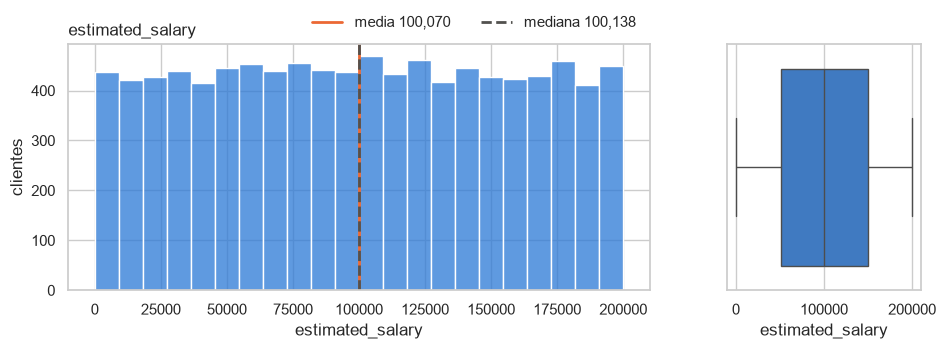

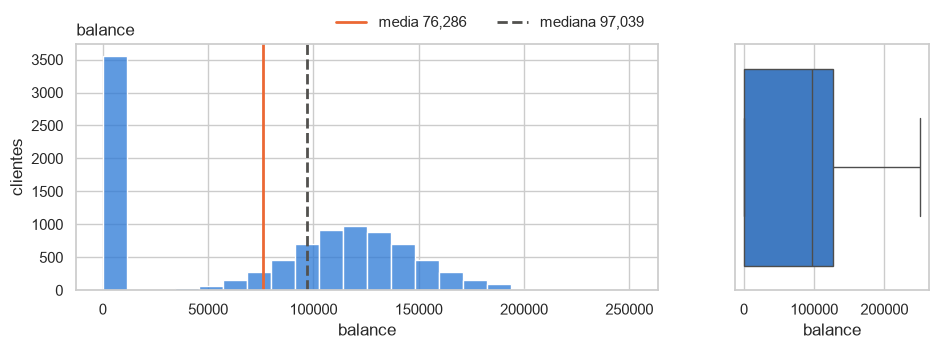

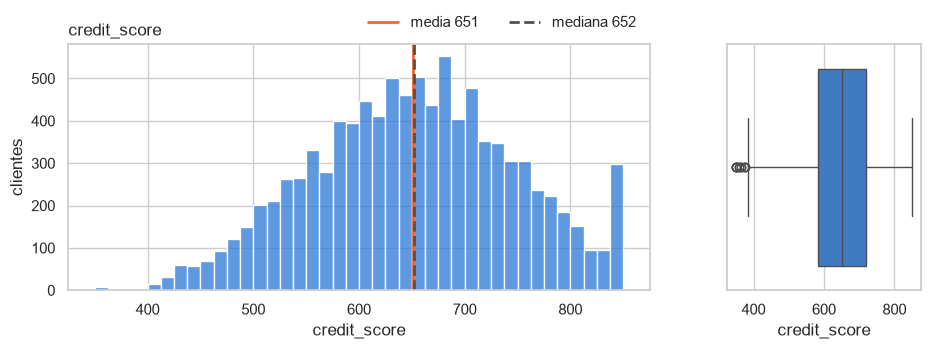

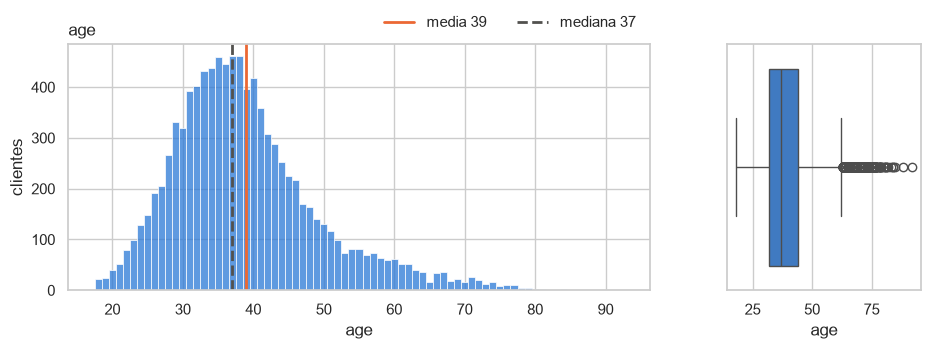

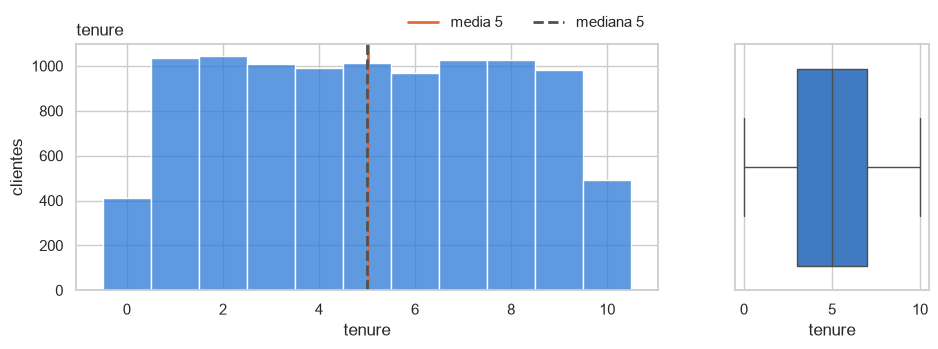

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
sns.set_theme(style="whitegrid")


def graficar_distribucion(datos, columna, discreta=False):
    """Histograma y diagrama de caja de una variable numérica, con su media y su mediana."""
    valores = datos[columna].dropna()
    fig, (histograma, caja) = plt.subplots(1, 2, figsize=(11, 3.2), width_ratios=[3, 1])
    sns.histplot(valores, discrete=discreta, color=AZUL, edgecolor="white", ax=histograma)
    histograma.axvline(valores.mean(), color=NARANJA, linewidth=2, label=f"media {valores.mean():,.0f}")
    histograma.axvline(valores.median(), color=GRIS, linewidth=2, linestyle="--",
                       label=f"mediana {valores.median():,.0f}")
    histograma.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False)
    histograma.set_title(columna, loc="left")
    histograma.set_ylabel("clientes")
    sns.boxplot(x=valores, color=AZUL, ax=caja)
    plt.show()


for columna in ["estimated_salary", "balance", "credit_score"]:
    graficar_distribucion(datos, columna)
for columna in ["age", "tenure"]:
    graficar_distribucion(datos, columna, discreta=True)

Lectura de los gráficos:

- `estimated_salary` se reparte casi igual entre 0 y 200.000: la media (100.070) y la mediana (100.138) prácticamente coinciden, así que imputar los nulos y los salarios negativos con una o con otra da el mismo valor.
- `balance` tiene dos grupos: un 36 % de clientes con saldo 0 y el resto alrededor de 120.000. La media (76.286) queda arrastrada por los ceros hacia una zona con pocos clientes; la mediana (97.039) se ve menos afectada, por eso se imputa con la mediana.
- `credit_score` es casi simétrico (media 651, mediana 652). El pico en 850 es el máximo de la escala, no un error.
- `age` tiene sesgo a la derecha: la mitad central de los clientes tiene entre 32 y 44 años, y las edades mayores aparecen como atípicos en la caja, pero son edades posibles.
- `tenure` se reparte casi igual entre 1 y 9 años; 0 y 10 tienen cerca de la mitad de clientes que los demás años.

### 1.8 Variables categóricas, binarias y objetivo

Porcentaje de clientes en cada valor. El panel `churn` muestra el balance entre las dos clases.

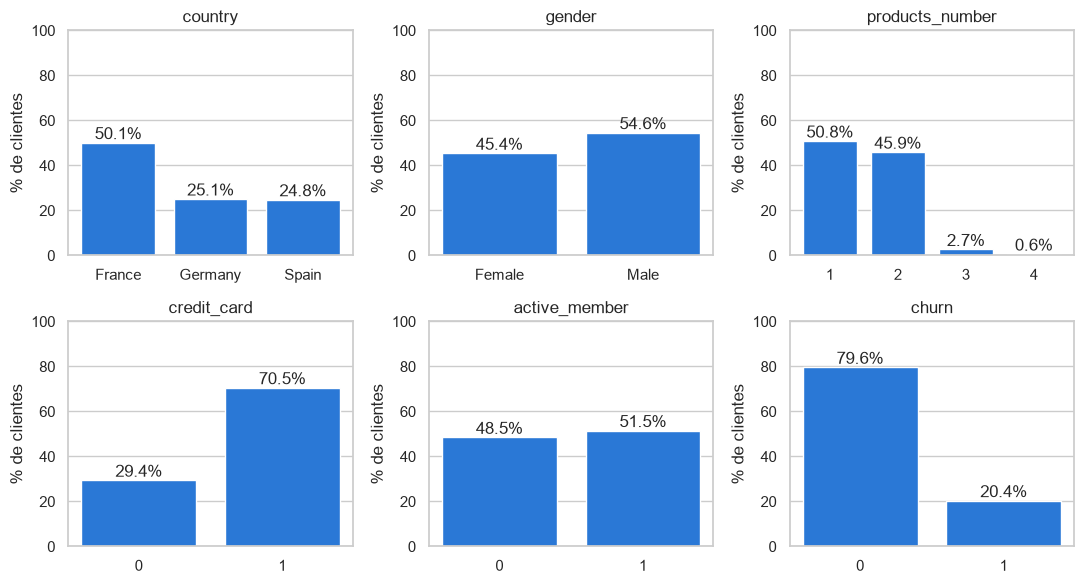

In [11]:
def graficar_porcentajes(datos, columnas):
    """Barras con el porcentaje de clientes de cada valor, un panel por columna."""
    fig, ejes = plt.subplots(2, 3, figsize=(11, 6))
    for eje, columna in zip(ejes.flat, columnas):
        porcentajes = datos[columna].value_counts(normalize=True).sort_index() * 100
        eje.bar(porcentajes.index.astype(str), porcentajes, color=AZUL)
        eje.bar_label(eje.containers[0], fmt="%.1f%%")
        eje.set_ylim(0, 100)
        eje.grid(False, axis="x")
        eje.set_title(columna)
        eje.set_ylabel("% de clientes")
    plt.tight_layout()
    plt.show()


graficar_porcentajes(datos, ["country", "gender", "products_number", "credit_card", "active_member", "churn"])

Lectura de los gráficos:

- La mitad de los clientes es de Francia; Alemania y España tienen un cuarto cada uno.
- El 97 % de los clientes tiene uno o dos productos; tres o cuatro productos son casos raros.
- El 20,4 % de los clientes abandonó el banco: las clases están desbalanceadas. Por eso la división se estratifica por `churn` y, al evaluar los modelos, la exactitud sola no basta (un modelo que siempre dice «no abandona» acierta el 79,6 %).

### 1.9 Relación de las variables con churn

**Variables numéricas.** Cada variable se compara entre los clientes que se quedan (0) y los que se van (1): diagramas de caja, media y mediana de cada grupo, y dos pruebas. La prueba t pregunta si las medias son distintas; Mann-Whitney, si los valores de un grupo tienden a ser mayores, sin suponer una distribución normal. Con un valor p menor que 0,05 la diferencia se considera real y no producto del azar.

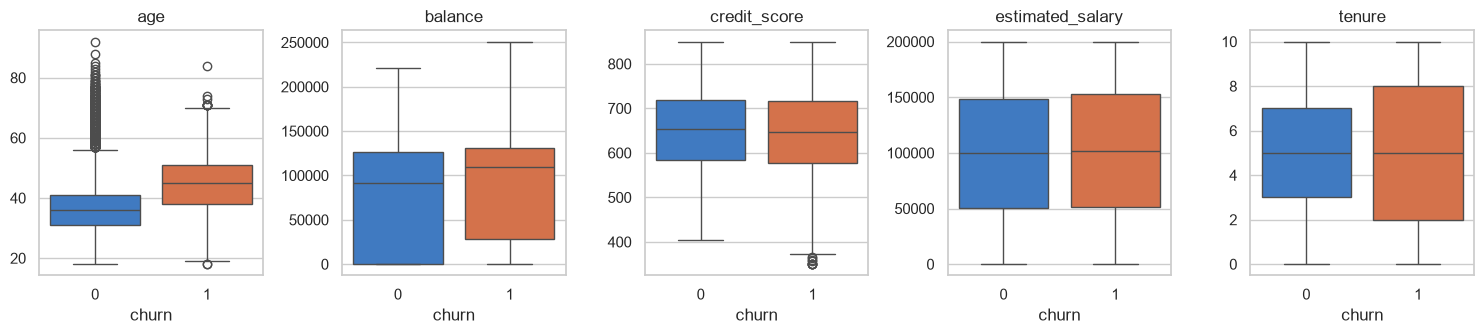

In [12]:
from scipy import stats
from scipy.stats.contingency import association

NUMERICAS = ["age", "balance", "credit_score", "estimated_salary", "tenure"]
CATEGORICAS = ["country", "gender", "products_number", "credit_card", "active_member"]


def graficar_cajas_por_churn(datos, columnas):
    """Diagrama de caja de cada variable para los que se quedan (0) y los que se van (1)."""
    fig, ejes = plt.subplots(1, len(columnas), figsize=(3 * len(columnas), 3.5))
    for eje, columna in zip(ejes, columnas):
        sns.boxplot(data=datos, x="churn", y=columna, hue="churn", palette=[AZUL, NARANJA], legend=False, ax=eje)
        eje.set_title(columna)
        eje.set_ylabel("")
    plt.tight_layout()
    plt.show()


graficar_cajas_por_churn(datos, NUMERICAS)

In [13]:
def comparar_por_churn(datos, columnas):
    """Media y mediana de cada grupo, y valores p de la prueba t y de Mann-Whitney."""
    filas = []
    for columna in columnas:
        se_quedan = datos.loc[datos["churn"] == 0, columna].dropna()
        se_van = datos.loc[datos["churn"] == 1, columna].dropna()
        filas.append({
            "variable": columna,
            "media se quedan": se_quedan.mean(),
            "media se van": se_van.mean(),
            "mediana se quedan": se_quedan.median(),
            "mediana se van": se_van.median(),
            "p prueba t": stats.ttest_ind(se_quedan, se_van, equal_var=False).pvalue,
            "p Mann-Whitney": stats.mannwhitneyu(se_quedan, se_van).pvalue,
        })
    return pd.DataFrame(filas).set_index("variable").round(4)


comparar_por_churn(datos, NUMERICAS)

,media se quedan,media se van,mediana se quedan,mediana se van,p prueba t,p Mann-Whitney
variable,,,,,,
age,37.4119,44.7657,36.00,45.000,0.0000,0.0000
balance,72564.2971,90774.5603,91835.16,109153.960,0.0000,0.0000
credit_score,651.9761,645.3111,654.00,646.000,0.0076,0.0157
estimated_salary,99754.2554,101300.4032,99654.13,102127.295,0.2907,0.2885
tenure,5.0345,4.9327,5.00,5.000,0.1611,0.1570


Lectura:

- `age` es la variable que más separa: los que se van tienen en promedio 44,8 años y los que se quedan 37,4 (medianas de 45 y 36). Las dos pruebas dan un valor p prácticamente 0. Coincide con lo observado en Metabase.
- `balance`: los que se van tienen saldos más altos (media de 90.775 frente a 72.564), y la diferencia es real.
- `estimated_salary`: como se vio en Metabase, el promedio de los que se quedan es un poco menor (99.754 frente a 101.300), pero ninguna prueba encuentra una diferencia real (p = 0,29): es azar.
- `credit_score`: la diferencia es significativa (p < 0,05) pero muy pequeña (652 frente a 645 de media). Con 10.000 clientes, hasta 7 puntos de diferencia salen significativos; eso no la hace importante.
- `tenure`: no hay diferencia (p de 0,16).

**Variables categóricas.** Para cada categoría se calcula el porcentaje de clientes que se va; el título muestra la tasa general (20,4 %). El chi-cuadrado dice si las diferencias entre categorías son reales (p < 0,05) y la V de Cramér, qué tan fuerte es la relación: 0 es ninguna y 1 es total.

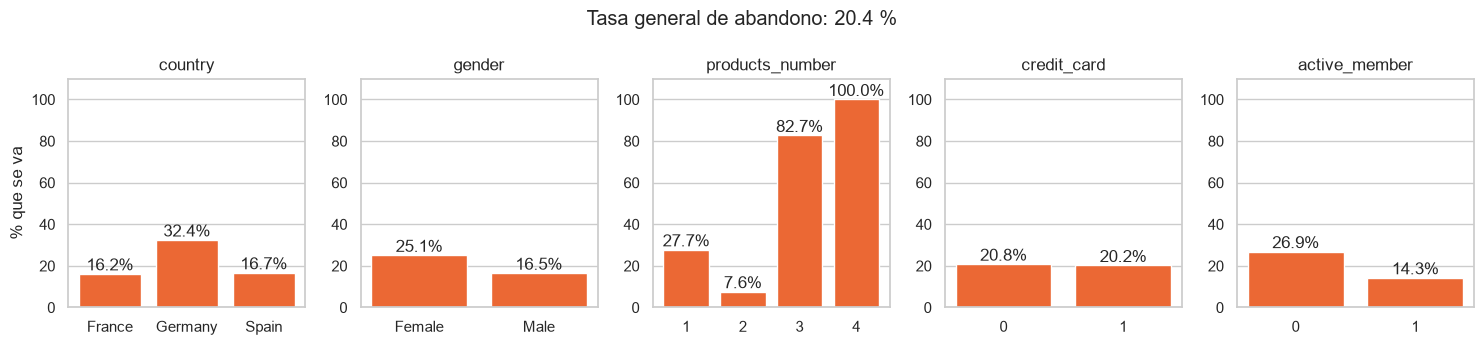

In [14]:
def graficar_tasa_de_abandono(datos, columnas):
    """Porcentaje de clientes que se va en cada valor de cada variable; el título muestra la tasa general."""
    tasa_general = datos["churn"].mean() * 100
    fig, ejes = plt.subplots(1, len(columnas), figsize=(3 * len(columnas), 3.5))
    for eje, columna in zip(ejes, columnas):
        tasa = datos.groupby(columna)["churn"].mean() * 100
        eje.bar(tasa.index.astype(str), tasa, color=NARANJA)
        eje.bar_label(eje.containers[0], fmt="%.1f%%")
        eje.set_ylim(0, 110)
        eje.grid(False, axis="x")
        eje.set_title(columna)
    ejes[0].set_ylabel("% que se va")
    fig.suptitle(f"Tasa general de abandono: {tasa_general:.1f} %")
    plt.tight_layout()
    plt.show()


graficar_tasa_de_abandono(datos, CATEGORICAS)

In [15]:
def probar_relacion_con_churn(datos, columnas):
    """Valor p del chi-cuadrado y V de Cramér entre cada variable y churn, de la relación más fuerte a la más débil."""
    filas = []
    for columna in columnas:
        tabla = pd.crosstab(datos[columna], datos["churn"])
        filas.append({
            "variable": columna,
            "p chi-cuadrado": stats.chi2_contingency(tabla).pvalue,
            "V de Cramér": association(tabla, method="cramer"),
        })
    return pd.DataFrame(filas).set_index("variable").sort_values("V de Cramér", ascending=False).round(4)


probar_relacion_con_churn(datos, CATEGORICAS)

,p chi-cuadrado,V de Cramér
variable,,
products_number,0.0000,0.3878
country,0.0000,0.1736
active_member,0.0000,0.1561
gender,0.0000,0.1065
credit_card,0.4924,0.0071


Lectura:

- `products_number` tiene la relación más fuerte (V = 0,39). Con 2 productos se va el 7,6 % y con 1 el 27,7 %; con 3 y 4 se va la mayoría (82,7 % y 100 %), aunque son pocos clientes (266 y 60).
- `country`: como se vio en Metabase, en Alemania se va el 32,4 %, el doble que en Francia (16,2 %) y España (16,7 %), que son muy parecidas (V = 0,17).
- `active_member`: los inactivos se van casi el doble que los activos (26,9 % frente a 14,3 %; V = 0,16).
- `gender`: se van más las mujeres (25,1 %) que los hombres (16,5 %). La relación es real pero débil (V = 0,11).
- `credit_card` no tiene relación con el abandono (p = 0,49; V = 0,01).

**Abandono por rangos de edad.** En Metabase, la tasa de abandono por edad forma una curva que sube hasta cerca de los 55 años y luego baja, con un valor alto aislado entre los 80 y los 85 años. Para revisarlo se agrupan las edades en rangos de 5 años y se cuenta cuántos clientes hay en cada uno. La línea punteada es la tasa general (20,4 %).

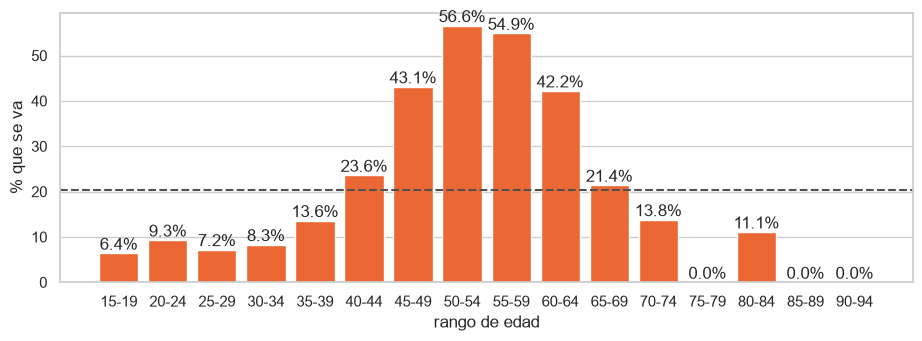

,clientes,se_van,% se van
age,,,
15-19,47,3,6.4
20-24,398,37,9.3
25-29,1145,83,7.2
30-34,1982,165,8.3
35-39,2224,302,13.6
40-44,1624,384,23.6
45-49,915,394,43.1
50-54,502,284,56.6
55-59,350,192,54.9


In [16]:
rangos_de_edad = pd.cut(datos["age"], range(15, 100, 5), right=False,
                        labels=[f"{inicio}-{inicio + 4}" for inicio in range(15, 95, 5)])
abandono_por_edad = datos.groupby(rangos_de_edad, observed=True)["churn"].agg(clientes="size", se_van="sum")
abandono_por_edad["% se van"] = (abandono_por_edad["se_van"] / abandono_por_edad["clientes"] * 100).round(1)

fig, eje = plt.subplots(figsize=(11, 3.5))
eje.bar(abandono_por_edad.index.astype(str), abandono_por_edad["% se van"], color=NARANJA)
eje.bar_label(eje.containers[0], fmt="%.1f%%")
eje.axhline(datos["churn"].mean() * 100, color=GRIS, linestyle="--")
eje.set_ylabel("% que se va")
eje.set_xlabel("rango de edad")
eje.grid(False, axis="x")
plt.show()

abandono_por_edad

In [17]:
datos[datos["age"] >= 80].sort_values("age")

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
2653,652.0,France,Female,80.0,4.0,0.00,2,1,1,188603.07,0
2382,624.0,France,Male,80.0,3.0,0.00,1,1,1,65801.44,0
519,850.0,France,Female,81.0,1.0,0.00,2,1,1,59568.24,0
1799,682.0,Germany,Male,81.0,6.0,122029.15,1,1,1,50783.88,0
5762,711.0,France,Female,81.0,6.0,0.00,2,1,1,72276.24,0
3775,700.0,France,Female,82.0,2.0,0.00,2,0,1,182055.36,0
1099,678.0,Germany,Male,83.0,6.0,123356.63,1,0,1,92934.41,0
3779,537.0,Germany,Male,84.0,8.0,92242.34,1,1,1,186235.98,0
5993,408.0,France,Female,84.0,8.0,87873.39,1,0,0,188484.52,1
2955,787.0,France,Female,85.0,10.0,0.00,2,1,1,116537.96,0


Lectura:

- La tasa de abandono sube con la edad hasta un máximo entre los 50 y los 60 años (56,6 % y 54,9 %): más de la mitad de esos clientes se fue. Después baja, y entre los 75 y los 80 años no se fue ninguno de 38 clientes.
- El 50 % que muestra Metabase cerca de los 84 años no es un patrón. Ese intervalo tiene 2 clientes de 84 años y se fue 1. En todo el rango de 80 a 85 hay 9 clientes y solo se fue 1 (11,1 %). Con tan pocos clientes, una sola persona mueve la tasa decenas de puntos.
- Esa clienta (84 años, Francia) es inactiva y tiene un solo producto, dos características que se asocian con más abandono; su salida se explica mejor por eso que por la edad.

### 1.10 Conclusiones de la exploración

Los datos se exploraron en dos frentes: gráficos en Metabase, sobre las tablas `churn` y `churn_limpio`, y el código de este notebook.

**Calidad de los datos**

- El archivo trae 10.045 registros y 11 columnas. 45 registros eran copias exactas de otros; al quitarlos quedan 10.000 clientes.
- `country` y `gender` venían escritos de varias formas (mayúsculas, espacios al final, `M` y `F`). Se unificaron en 3 países y 2 géneros.
- Hay pocos valores imposibles: 6 edades por debajo de 18 o por encima de 100 años, 3 antigüedades (`tenure`) fuera de 0 a 10, 3 salarios negativos y 4 puntajes de crédito fuera de 300 a 850. Se marcaron como nulos en lugar de recortarlos, porque estaban lejos del rango válido.
- Después de la limpieza, ninguna columna tiene más del 3,6 % de nulos.

**Decisiones de tratamiento**

- La edad y la antigüedad se consideran importantes para predecir el abandono, así que sus nulos no se reemplazan por una medida estadística. Por eso, antes de dividir los datos, se eliminan los clientes con edad o antigüedad nula.
- Los 200 nulos de `balance` no son saldos en cero: son datos faltantes. Como el 36 % de los clientes tiene saldo 0, la media queda arrastrada hacia abajo, y por eso se imputan con la mediana.
- Los salarios se reparten de forma casi plana y su media y su mediana coinciden, así que los nulos y los salarios negativos se imputan con ese valor central.
- 228 clientes tienen un puntaje de crédito de 850. Es el máximo de la escala, no un error, y se deja como está.

**Relación con el abandono**

- La edad es la variable numérica que más separa a quienes se van: tienen en promedio 45 años frente a 37, y el abandono pasa del 50 % entre los 50 y los 60 años.
- En Alemania se va el doble de clientes que en Francia y España (32 % frente a 16-17 %).
- El número de productos tiene la relación más fuerte: con dos productos se va el 8 %, con uno el 28 % y con tres o cuatro la mayoría.
- Los miembros inactivos y las mujeres abandonan más.
- El salario, la antigüedad y tener tarjeta de crédito no muestran relación con el abandono.

**Lo que muestran los datos**

- La mitad de los clientes es de Francia, y el 97 % tiene uno o dos productos.
- El 20,4 % de los clientes (2.037 de 10.000) abandonó el banco. Las clases están desbalanceadas: por eso la división se estratifica por `churn` y los modelos no se evalúan solo con la exactitud.

### 1.11 División e imputación

Los datos se dividen en entrenamiento, validación y prueba (60 %, 20 % y 20 %), estratificando por `churn` y con `random_state=42`. Los nulos de `credit_score`, `balance` y `estimated_salary` se imputan con la mediana calculada solo con entrenamiento, para no filtrar información de validación y prueba.

`age` y `tenure` son variables importantes para predecir el abandono y sus nulos no se reemplazan por una medida estadística: antes de dividir se eliminan los clientes con alguno de esos dos datos vacío.

In [18]:
from sklearn.model_selection import train_test_split

datos_modelo = datos.dropna(subset=["age", "tenure"])
print(f"Se eliminan {len(datos) - len(datos_modelo)} clientes con edad o antigüedad nula; quedan {len(datos_modelo)}")

entrenamiento, resto = train_test_split(datos_modelo, test_size=0.4, stratify=datos_modelo["churn"], random_state=42)
validacion, prueba = train_test_split(resto, test_size=0.5, stratify=resto["churn"], random_state=42)

COLUMNAS_A_IMPUTAR = ["credit_score", "balance", "estimated_salary"]
medianas = entrenamiento[COLUMNAS_A_IMPUTAR].median()
entrenamiento = entrenamiento.fillna(medianas)
validacion = validacion.fillna(medianas)
prueba = prueba.fillna(medianas)

print("Medianas de entrenamiento:", medianas.round(2).to_dict())
for nombre, conjunto in [("entrenamiento", entrenamiento), ("validación", validacion), ("prueba", prueba)]:
    print(f"{nombre}: {len(conjunto)} registros, {conjunto['churn'].mean():.1%} de churn, "
          f"nulos restantes: {conjunto.isna().sum().sum()}")

Se eliminan 309 clientes con edad o antigüedad nula; quedan 9691
Medianas de entrenamiento: {'credit_score': 653.0, 'balance': 97221.52, 'estimated_salary': 100335.55}
entrenamiento: 5814 registros, 20.5% de churn, nulos restantes: 0
validación: 1938 registros, 20.5% de churn, nulos restantes: 0
prueba: 1939 registros, 20.5% de churn, nulos restantes: 0


## 2. Entrenamiento del modelo

### 2.1 Variables del modelo

- Se descartan `credit_card`, `estimated_salary` y `tenure`: en la sección 1.9 no mostraron relación con el abandono (p > 0,05).
- `products_number` entra como categórica (one-hot), porque su relación con el abandono no es una línea recta: se va el 28 %, el 8 %, el 83 % y el 100 % con 1, 2, 3 y 4 productos.
- `country` y `gender` también se codifican con one-hot; `active_member` ya es 0 o 1.
- Las numéricas se escalan para que la regresión logística las compare en la misma escala.

La preparación y el modelo van juntos en un `Pipeline`. Así, dentro de la validación cruzada, el escalador y la codificación se ajustan solo con las particiones de entrenamiento (sin fuga de datos), y el mismo objeto sirve después para predecir y para interpretar el modelo con las variables originales.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERICAS_MODELO = ["age", "balance", "credit_score"]
CATEGORICAS_MODELO = ["country", "gender", "products_number"]
BINARIAS_MODELO = ["active_member"]
VARIABLES_MODELO = NUMERICAS_MODELO + CATEGORICAS_MODELO + BINARIAS_MODELO

X_entrenamiento, y_entrenamiento = entrenamiento[VARIABLES_MODELO], entrenamiento["churn"]
X_validacion, y_validacion = validacion[VARIABLES_MODELO], validacion["churn"]
X_prueba, y_prueba = prueba[VARIABLES_MODELO], prueba["churn"]


def crear_preparacion():
    """Escala las numéricas, codifica las categóricas con one-hot y deja pasar las binarias sin cambios."""
    return ColumnTransformer([
        ("escalar", StandardScaler(), NUMERICAS_MODELO),
        ("one_hot", OneHotEncoder(drop="first"), CATEGORICAS_MODELO),
    ], remainder="passthrough")


crear_preparacion().fit(X_entrenamiento).get_feature_names_out()

array(['escalar__age', 'escalar__balance', 'escalar__credit_score',
       'one_hot__country_Germany', 'one_hot__country_Spain',
       'one_hot__gender_Male', 'one_hot__products_number_2',
       'one_hot__products_number_3', 'one_hot__products_number_4',
       'remainder__active_member'], dtype=object)

### 2.2 Regresión logística

`GridSearchCV` prueba 8 combinaciones de hiperparámetros con validación cruzada estratificada de 5 partes sobre el conjunto de entrenamiento (40 entrenamientos) y se queda con la de mayor F1 promedio:

- `C`: fuerza de la regularización. Valores pequeños dan un modelo más simple.
- `class_weight`: sin pesos o `balanced`, que da más peso a los clientes que se van para compensar el desbalance.

Se optimiza el F1 y no la exactitud porque, con un 20 % de abandono, la exactitud premia a un modelo que no detecta a nadie.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

VALIDACION_CRUZADA = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def buscar_hiperparametros(modelo, hiperparametros):
    """Prueba cada combinación con validación cruzada sobre entrenamiento y se queda con la de mayor F1."""
    pipeline = Pipeline([("preparacion", crear_preparacion()), ("modelo", modelo)])
    busqueda = GridSearchCV(pipeline, hiperparametros, cv=VALIDACION_CRUZADA, scoring="f1", n_jobs=-1)
    busqueda.fit(X_entrenamiento, y_entrenamiento)
    return busqueda


def resumir_busqueda(busqueda):
    """F1 promedio y desviación entre particiones de cada combinación probada, de la mejor a la peor."""
    resultados = pd.DataFrame(busqueda.cv_results_)
    columnas = [c for c in resultados.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    return (resultados[columnas]
            .rename(columns={"mean_test_score": "F1 promedio", "std_test_score": "desviación"})
            .sort_values("F1 promedio", ascending=False)
            .fillna("None")  # pandas muestra class_weight=None como NaN
            .round(4))


busqueda_logistica = buscar_hiperparametros(
    LogisticRegression(max_iter=1000),
    {"modelo__C": [0.01, 0.1, 1, 10], "modelo__class_weight": [None, "balanced"]},
)
print("Mejor combinación:", busqueda_logistica.best_params_)
resumir_busqueda(busqueda_logistica)

Mejor combinación: {'modelo__C': 10, 'modelo__class_weight': 'balanced'}


,param_modelo__C,param_modelo__class_weight,F1 promedio,desviación
7,10.00,balanced,0.5625,0.0309
5,1.00,balanced,0.5615,0.0309
3,0.10,balanced,0.5588,0.0276
1,0.01,balanced,0.5398,0.0314
6,10.00,None,0.4969,0.0241
4,1.00,None,0.4950,0.0239
2,0.10,None,0.4788,0.0227
0,0.01,None,0.2865,0.0226


### 2.3 Resultado en entrenamiento y validación

El mejor modelo se evalúa en entrenamiento y en validación: una diferencia grande entre los dos indicaría sobreajuste. El conjunto de prueba no se usa aquí. Se reserva para evaluar una sola vez el modelo elegido, después de comparar todos los modelos en validación.

In [21]:
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)


def calcular_metricas(modelo, X, y):
    """Exactitud, precisión, recall y F1 con el umbral de 0,5; AUC y AP con las probabilidades."""
    prediccion = modelo.predict(X)
    probabilidad = modelo.predict_proba(X)[:, 1]
    return {
        "exactitud": accuracy_score(y, prediccion),
        "precisión": precision_score(y, prediccion),
        "recall": recall_score(y, prediccion),
        "F1": f1_score(y, prediccion),
        "AUC": roc_auc_score(y, probabilidad),
        "AP": average_precision_score(y, probabilidad),
    }


logistica = busqueda_logistica.best_estimator_
pd.DataFrame({
    "entrenamiento": calcular_metricas(logistica, X_entrenamiento, y_entrenamiento),
    "validación": calcular_metricas(logistica, X_validacion, y_validacion),
}).round(3)

,entrenamiento,validación
exactitud,0.762,0.775
precisión,0.452,0.468
recall,0.749,0.730
F1,0.564,0.571
AUC,0.836,0.830
AP,0.626,0.613


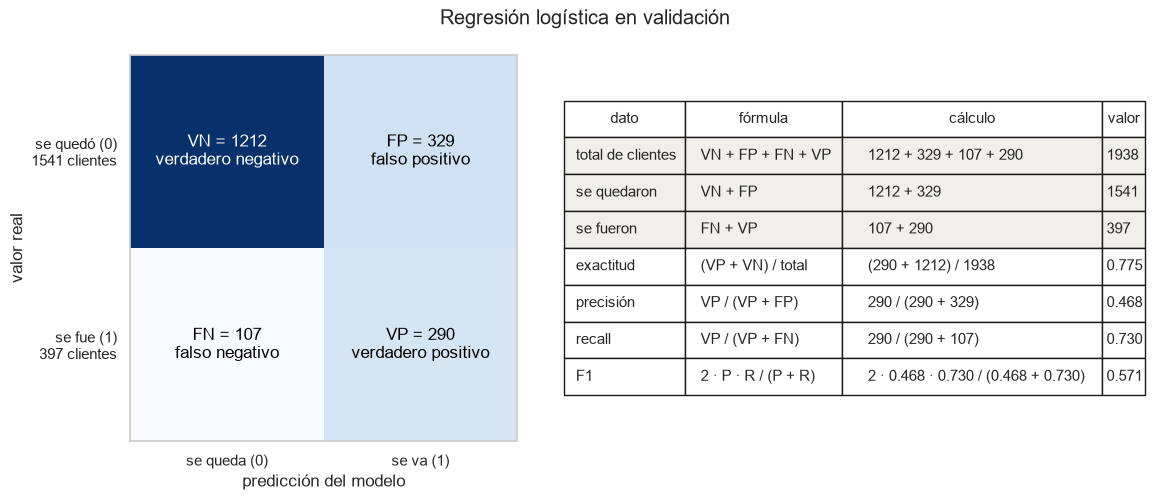

In [22]:
def graficar_matriz_de_confusion(modelo, X, y, titulo):
    """Matriz de confusión con el nombre de cada cuadrante y, al lado, los totales y las métricas que salen de ella."""
    vn, fp, fn, vp = confusion_matrix(y, modelo.predict(X)).ravel()
    precision, recall = vp / (vp + fp), vp / (vp + fn)
    cuadrantes = [[("VN", "verdadero negativo", vn), ("FP", "falso positivo", fp)],
                  [("FN", "falso negativo", fn), ("VP", "verdadero positivo", vp)]]
    filas_tabla = [
        ["total de clientes", "VN + FP + FN + VP", f"{vn} + {fp} + {fn} + {vp}", f"{len(y)}"],
        ["se quedaron", "VN + FP", f"{vn} + {fp}", f"{vn + fp}"],
        ["se fueron", "FN + VP", f"{fn} + {vp}", f"{fn + vp}"],
        ["exactitud", "(VP + VN) / total", f"({vp} + {vn}) / {len(y)}", f"{(vp + vn) / len(y):.3f}"],
        ["precisión", "VP / (VP + FP)", f"{vp} / ({vp} + {fp})", f"{precision:.3f}"],
        ["recall", "VP / (VP + FN)", f"{vp} / ({vp} + {fn})", f"{recall:.3f}"],
        ["F1", "2 · P · R / (P + R)", f"2 · {precision:.3f} · {recall:.3f} / ({precision:.3f} + {recall:.3f})",
         f"{2 * precision * recall / (precision + recall):.3f}"],
    ]

    fig, (eje_matriz, eje_tabla) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.3]})
    eje_matriz.imshow([[vn, fp], [fn, vp]], cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            sigla, nombre, valor = cuadrantes[fila][columna]
            color = "white" if valor > max(vn, fp, fn, vp) / 2 else "black"
            eje_matriz.text(columna, fila, f"{sigla} = {valor}\n{nombre}", ha="center", va="center", color=color, fontsize=12)
    eje_matriz.set_xticks([0, 1], ["se queda (0)", "se va (1)"])
    eje_matriz.set_yticks([0, 1], [f"se quedó (0)\n{vn + fp} clientes", f"se fue (1)\n{fn + vp} clientes"])
    eje_matriz.set_xlabel("predicción del modelo")
    eje_matriz.set_ylabel("valor real")
    eje_matriz.grid(False)

    eje_tabla.axis("off")
    tabla = eje_tabla.table(cellText=filas_tabla, colLabels=["dato", "fórmula", "cálculo", "valor"], loc="center", cellLoc="left")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(11)
    tabla.auto_set_column_width(range(4))
    tabla.scale(1.1, 2.2)
    for fila in range(1, 4):  # las tres primeras filas de datos son conteos de clientes, no métricas
        for columna in range(4):
            tabla[fila, columna].set_facecolor("#f0efec")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


graficar_matriz_de_confusion(logistica, X_validacion, y_validacion, "Regresión logística en validación")

Lectura:

- Validación tiene 1.938 clientes: 1.541 se quedaron (VN + FP) y 397 se fueron (FN + VP).
- De los 397 clientes de validación que se fueron (VP + FN), el modelo detecta 290 (recall de 0,730) y se le escapan 107.
- De los 619 clientes que marca como en riesgo (VP + FP), 290 se fueron de verdad (precisión de 0,468): por cada cliente bien detectado hay un poco más de una falsa alarma.
- La exactitud (0,775) cuenta los aciertos de las dos clases. Como el 80 % de los clientes se queda, los 1.212 verdaderos negativos pesan mucho en ella; por eso el modelo se elige con el F1.

### 2.4 Random Forest

Un Random Forest entrena muchos árboles de decisión, cada uno con una muestra distinta de clientes y de variables, y predice por votación: si 180 de 300 árboles dicen que un cliente se va, su probabilidad de irse es 180 / 300 = 0,6. A diferencia de la regresión logística, capta relaciones que no son una línea recta (el abandono sube con la edad hasta los 55 años y luego baja) y combinaciones entre variables (por ejemplo, ser inactivo y tener un solo producto).

Se prueban 18 combinaciones con la misma validación cruzada (90 entrenamientos):

- `max_depth`: cuántas preguntas seguidas puede hacer cada árbol (5, 10 o sin límite). Árboles más profundos memorizan más.
- `min_samples_leaf`: mínimo de clientes en cada hoja (1, 5 o 20). Valores más grandes dan árboles más simples.
- `class_weight`: igual que en la regresión logística.

`n_estimators` se fija en 300 árboles: agregar árboles no causa sobreajuste, solo estabiliza la votación y hace más lento el entrenamiento. La preparación es la misma; escalar no cambia nada en los árboles, pero se mantiene para usar las mismas funciones.

In [23]:
from sklearn.ensemble import RandomForestClassifier

busqueda_random_forest = buscar_hiperparametros(
    RandomForestClassifier(n_estimators=300, random_state=42),
    {"modelo__max_depth": [5, 10, None], "modelo__min_samples_leaf": [1, 5, 20],
     "modelo__class_weight": [None, "balanced"]},
)
print("Mejor combinación:", busqueda_random_forest.best_params_)
resumir_busqueda(busqueda_random_forest)

Mejor combinación: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1}


,param_modelo__class_weight,param_modelo__max_depth,param_modelo__min_samples_leaf,F1 promedio,desviación
12,balanced,10,1,0.6057,0.0355
16,balanced,None,5,0.6005,0.0305
13,balanced,10,5,0.6001,0.0335
4,None,10,5,0.5971,0.0373
9,balanced,5,1,0.5970,0.0300
7,None,None,5,0.5964,0.0366
10,balanced,5,5,0.5954,0.0312
15,balanced,None,1,0.5912,0.0318
11,balanced,5,20,0.5900,0.0291
14,balanced,10,20,0.5895,0.0284


In [24]:
random_forest = busqueda_random_forest.best_estimator_
pd.DataFrame({
    "entrenamiento": calcular_metricas(random_forest, X_entrenamiento, y_entrenamiento),
    "validación": calcular_metricas(random_forest, X_validacion, y_validacion),
}).round(3)

,entrenamiento,validación
exactitud,0.889,0.836
precisión,0.671,0.582
recall,0.899,0.708
F1,0.768,0.639
AUC,0.962,0.864
AP,0.885,0.712


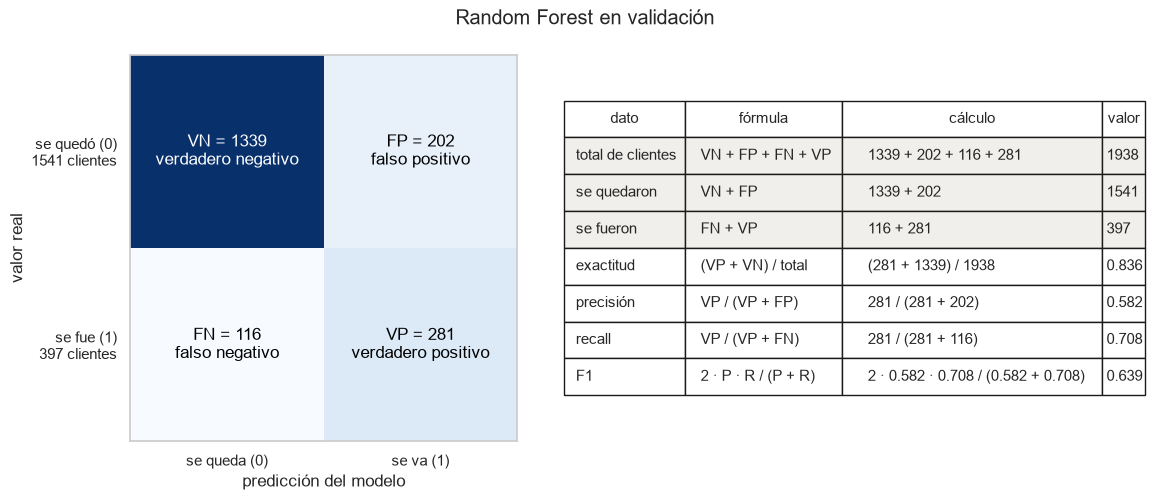

In [25]:
graficar_matriz_de_confusion(random_forest, X_validacion, y_validacion, "Random Forest en validación")

Lectura:

- La mejor combinación usa `class_weight="balanced"`, árboles de profundidad 10 y hojas de al menos 1 cliente, con un F1 promedio de 0,606 en la validación cruzada (la regresión logística llegó a 0,563). Sin balancear y con árboles de profundidad 5, el F1 cae a 0,51-0,54.
- Entre entrenamiento y validación hay distancia (F1 de 0,768 frente a 0,639; AUC de 0,962 frente a 0,864): el bosque memoriza parte del entrenamiento. La regresión logística casi no tenía esa diferencia (0,564 frente a 0,571). Para elegir cuenta el resultado en validación, que son clientes que el modelo no vio.
- Frente a la regresión logística en validación, detecta casi los mismos clientes que se van (281 frente a 290; recall de 0,708 frente a 0,730), pero con 127 falsas alarmas menos (202 frente a 329). La precisión sube de 0,468 a 0,582: de cada 100 clientes marcados en riesgo, se van 58 en lugar de 47.
- El F1 en validación pasa de 0,571 a 0,639 y el AUC, de 0,830 a 0,864.

### 2.5 Gradient Boosting

Gradient Boosting también usa muchos árboles, pero en lugar de entrenarlos por separado y ponerlos a votar, los entrena uno detrás de otro: cada árbol nuevo aprende a corregir los errores que dejaron los anteriores. Dicho de forma simplificada: si después de los primeros árboles un cliente que se fue tiene una probabilidad de 0,20, el error es 1 − 0,20 = 0,80. El siguiente árbol aprende a corregir ese error, pero solo se aplica una fracción (`learning_rate`), así que la probabilidad sube poco a poco en lugar de saltar.

Se usa `HistGradientBoostingClassifier`, la versión rápida de scikit-learn: agrupa los valores de cada variable en intervalos antes de buscar los cortes y acepta `class_weight` como los modelos anteriores.

Hiperparámetros que se prueban (36 combinaciones, 180 entrenamientos):

- `learning_rate`: cuánto corrige cada árbol (0,05, 0,1 o 0,2).
- `max_depth`: profundidad de cada árbol (1, 2, 3 o 5). Aquí los árboles son pequeños a propósito: cada uno solo corrige un poco.
- `max_iter`: cuántos árboles se encadenan (100, 300 o 500). A diferencia del Random Forest, aquí más árboles sí pueden sobreajustar, porque cada uno sigue corrigiendo el entrenamiento.
- `class_weight` se fija en `balanced`: en la regresión logística y en el Random Forest siempre fue mejor que no balancear.

En una primera prueba con una cuadrícula más pequeña (`learning_rate` de 0,05 y 0,1, profundidad de 2 a 5, 100 y 300 árboles) la mejor combinación quedó en el borde de los tres hiperparámetros. Por eso, como pide la guía, la cuadrícula se amplió hacia esos bordes.

In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

busqueda_gradient_boosting = buscar_hiperparametros(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    {"modelo__learning_rate": [0.05, 0.1, 0.2], "modelo__max_depth": [1, 2, 3, 5],
     "modelo__max_iter": [100, 300, 500]},
)
print("Mejor combinación:", busqueda_gradient_boosting.best_params_)
resumir_busqueda(busqueda_gradient_boosting).head(10)

Mejor combinación: {'modelo__learning_rate': 0.2, 'modelo__max_depth': 3, 'modelo__max_iter': 100}


,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__max_iter,F1 promedio,desviación
30,0.20,3,100,0.6125,0.0345
17,0.10,2,500,0.6102,0.0307
16,0.10,2,300,0.6100,0.0334
19,0.10,3,300,0.6095,0.0291
7,0.05,3,300,0.6071,0.0326
10,0.05,5,300,0.6063,0.0335
21,0.10,5,100,0.6060,0.0282
27,0.20,2,100,0.6059,0.0299
28,0.20,2,300,0.6056,0.0312
5,0.05,2,500,0.6053,0.0331


In [27]:
gradient_boosting = busqueda_gradient_boosting.best_estimator_
pd.DataFrame({
    "entrenamiento": calcular_metricas(gradient_boosting, X_entrenamiento, y_entrenamiento),
    "validación": calcular_metricas(gradient_boosting, X_validacion, y_validacion),
}).round(3)

,entrenamiento,validación
exactitud,0.827,0.818
precisión,0.553,0.542
recall,0.805,0.725
F1,0.656,0.621
AUC,0.907,0.863
AP,0.764,0.713


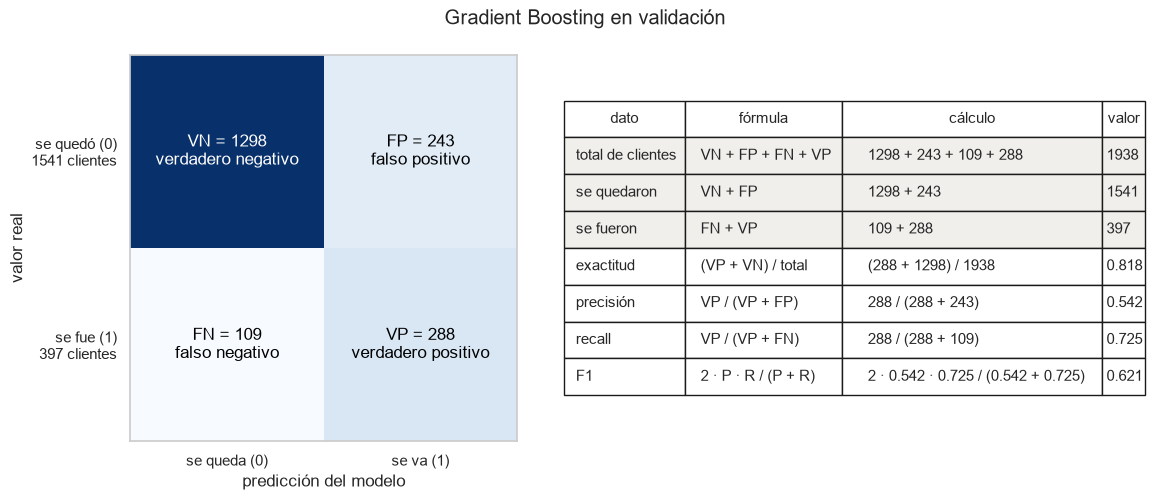

In [28]:
graficar_matriz_de_confusion(gradient_boosting, X_validacion, y_validacion, "Gradient Boosting en validación")

Lectura:

- La mejor combinación usa `learning_rate` de 0,2, árboles de profundidad 3 y 100 árboles, con un F1 promedio de 0,6125 en la validación cruzada. Sigue en el borde de `learning_rate` y de `max_iter`, pero las 10 mejores combinaciones están entre 0,605 y 0,6125: se diferencian en menos de una desviación (0,03). Ampliar más la cuadrícula no cambiaría el resultado de forma apreciable.
- Se sobreajusta poco: el F1 pasa de 0,656 en entrenamiento a 0,621 en validación (en el Random Forest pasaba de 0,768 a 0,639).
- En validación queda entre los dos modelos anteriores: detecta 288 de los 397 clientes que se fueron (la regresión logística 290 y el Random Forest 281) con 243 falsas alarmas (329 y 202). Su F1 es 0,621, frente a 0,571 de la regresión logística y 0,639 del Random Forest.
- Su AUC (0,863) y su AP (0,713) son prácticamente iguales a los del Random Forest (0,864 y 0,712): ordenan a los clientes por riesgo casi igual de bien.

### 2.6 Comparación de los modelos

Una columna por modelo, con la mejor combinación de hiperparámetros de cada búsqueda:

- **hiperparámetros**: la combinación elegida por `GridSearchCV`. En Gradient Boosting, `class_weight` está fijo en `balanced` y por eso no aparece.
- **F1 validación cruzada**: promedio y desviación del F1 en las 5 particiones de entrenamiento.
- **F1 entrenamiento**: F1 sobre todo el conjunto de entrenamiento, para compararlo con el de validación.
- **métricas en validación**: exactitud, precisión, recall y F1 con el umbral de 0,5; AUC y AP con las probabilidades.
- **VP, FP, FN y VN**: los cuadrantes de la matriz de confusión en validación (397 clientes se fueron y 1.541 se quedaron).

In [29]:
def comparar_modelos(busquedas):
    """Una columna por modelo: hiperparámetros, F1 en validación cruzada y entrenamiento, y resultados en validación."""
    tabla = {}
    for nombre, busqueda in busquedas.items():
        modelo = busqueda.best_estimator_
        columna = {
            "hiperparámetros": ", ".join(f"{clave.removeprefix('modelo__')}={valor}"
                                         for clave, valor in busqueda.best_params_.items()),
            "F1 validación cruzada (promedio)": round(busqueda.best_score_, 3),
            "F1 validación cruzada (desviación)": round(busqueda.cv_results_["std_test_score"][busqueda.best_index_], 3),
            "F1 entrenamiento": round(calcular_metricas(modelo, X_entrenamiento, y_entrenamiento)["F1"], 3),
        }
        for metrica, valor in calcular_metricas(modelo, X_validacion, y_validacion).items():
            columna[f"{metrica} validación"] = round(valor, 3)
        vn, fp, fn, vp = confusion_matrix(y_validacion, modelo.predict(X_validacion)).ravel()
        columna.update({"VP validación": vp, "FP validación": fp, "FN validación": fn, "VN validación": vn})
        tabla[nombre] = columna
    return pd.DataFrame(tabla)


comparar_modelos({
    "regresión logística": busqueda_logistica,
    "Random Forest": busqueda_random_forest,
    "Gradient Boosting": busqueda_gradient_boosting,
})

,regresión logística,Random Forest,Gradient Boosting
hiperparámetros,"C=10, class_weight=balanced","class_weight=balanced, max_depth=10, min_samples_leaf=1","learning_rate=0.2, max_depth=3, max_iter=100"
F1 validación cruzada (promedio),0.563,0.606,0.613
F1 validación cruzada (desviación),0.031,0.035,0.035
F1 entrenamiento,0.564,0.768,0.656
exactitud validación,0.775,0.836,0.818
precisión validación,0.468,0.582,0.542
recall validación,0.73,0.708,0.725
F1 validación,0.571,0.639,0.621
AUC validación,0.83,0.864,0.863
AP validación,0.613,0.712,0.713


### 2.7 Conclusión: qué modelo conviene según el costo de la campaña

Los modelos se comparan por la ganancia anual que dejaría una campaña de retención dirigida a los clientes que cada uno marca en riesgo. Se usan los datos del enunciado:

- **r = 30 %**: proporción de clientes que se iban y la campaña logra retener.
- **V = ingreso anual por cliente**, entre 500.000 y 900.000 COP. Se calculan los dos extremos.
- **c = costo de la campaña por cliente contactado**. Todavía no tiene un valor, por eso se calcula hasta dónde puede llegar.

Cada modelo contacta a los clientes que marca en riesgo (VP + FP). Solo los VP se iban de verdad, y de ellos la campaña retiene el 30 %:

- ingreso anual de la campaña = VP × 30 % × V
- costo de la campaña = (VP + FP) × c
- **ganancia anual = VP × 30 % × V − (VP + FP) × c**

El **precio máximo** por cliente contactado es el costo con el que la ganancia queda en cero. Despejando c:

**precio máximo = V × 30 % × VP / (VP + FP) = ingreso anual × 30 % × proporción de contactados que sí se iban**

La proporción de contactados que sí se iban es la precisión del modelo. Las cuentas se hacen con los clientes de validación (1.938).

In [30]:
TASA_DE_EXITO = 0.30  # r: proporción de clientes que se iban y la campaña retiene (enunciado)
INGRESOS_ANUALES = [500_000, 900_000]  # V: ingreso anual por cliente en COP (enunciado)
MODELOS = {"regresión logística": logistica, "Random Forest": random_forest, "Gradient Boosting": gradient_boosting}


def contar_contactados(modelo):
    """Clientes de validación que el modelo marca en riesgo (VP + FP) y cuántos de ellos sí se iban (VP)."""
    vn, fp, fn, vp = confusion_matrix(y_validacion, modelo.predict(X_validacion)).ravel()
    return vp + fp, vp


def calcular_ganancia_anual(modelo, ingreso, costo_por_contacto):
    """VP × 30 % × ingreso anual − contactados × costo por contacto."""
    contactados, vp = contar_contactados(modelo)
    return vp * TASA_DE_EXITO * ingreso - contactados * costo_por_contacto


def calcular_precios_maximos(modelos):
    """Costo por contacto con el que la ganancia queda en cero: ingreso anual × 30 % × precisión."""
    filas = []
    for nombre, modelo in modelos.items():
        contactados, vp = contar_contactados(modelo)
        fila = {"modelo": nombre, "contactados (VP + FP)": contactados, "VP": vp,
                "% que sí se iba": round(vp / contactados * 100, 1)}
        for ingreso in INGRESOS_ANUALES:
            fila[f"precio máximo con V = {ingreso // 1000}k"] = round(ingreso * TASA_DE_EXITO * vp / contactados)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("modelo")


calcular_precios_maximos(MODELOS)

,contactados (VP + FP),VP,% que sí se iba,precio máximo con V = 500k,precio máximo con V = 900k
modelo,,,,,
regresión logística,619,290,46.8,70275,126494
Random Forest,483,281,58.2,87267,157081
Gradient Boosting,531,288,54.2,81356,146441


**Cuentas del precio máximo.** Con V = 500.000, cada cliente retenido vale 30 % × 500.000 = 150.000 COP al año; con V = 900.000, 30 % × 900.000 = 270.000.

| Modelo | Contactados | Sí se iban | Proporción | V = 500.000 | V = 900.000 |
|---|---|---|---|---|---|
| Random Forest | 281 + 202 = 483 | 281 | 281 / 483 = 58,2 % | 150.000 × 58,2 % = 87.267 | 270.000 × 58,2 % = 157.081 |
| Gradient Boosting | 288 + 243 = 531 | 288 | 288 / 531 = 54,2 % | 150.000 × 54,2 % = 81.356 | 270.000 × 54,2 % = 146.441 |
| Regresión logística | 290 + 329 = 619 | 290 | 290 / 619 = 46,8 % | 150.000 × 46,8 % = 70.275 | 270.000 × 46,8 % = 126.494 |

Si contactar a un cliente cuesta más que ese valor, la campaña pierde dinero con ese modelo. Random Forest tolera el costo más alto porque es el que tiene la mayor proporción de contactados que sí se iban.

**Costo de empate entre dos modelos.** Es el costo por contacto con el que dos modelos dejan la misma ganancia. Con Gradient Boosting frente a Random Forest:

- Gradient Boosting encuentra 288 − 281 = 7 clientes más que se iban. Eso le da 7 × 30 % × V = 2,1 × V de ingreso extra.
- Pero contacta 531 − 483 = 48 clientes más, que cuestan 48 × c.
- Empatan cuando 48 × c = 2,1 × V, es decir, c = 2,1 / 48 × V = 4,375 % de V: **21.875 COP** con V = 500.000 y **39.375 COP** con V = 900.000.

Por debajo de ese costo, los 7 clientes extra de Gradient Boosting valen más que sus 48 contactos extra. Por encima, pesa más el costo de esos contactos y gana Random Forest. Con la regresión logística, la misma cuenta da:

- frente a Gradient Boosting: 2 clientes más y 88 contactos más. 88 × c = 0,6 × V, así que c = 0,68 % de V (3.409 o 6.136 COP).
- frente a Random Forest: 9 clientes más y 136 contactos más. 136 × c = 2,7 × V, así que c = 1,99 % de V (9.926 o 17.868 COP).

In [31]:
def calcular_costo_de_empate(modelo_a, modelo_b, ingreso):
    """Costo por contacto con el que dos modelos dejan la misma ganancia anual."""
    contactados_a, vp_a = contar_contactados(modelo_a)
    contactados_b, vp_b = contar_contactados(modelo_b)
    return TASA_DE_EXITO * ingreso * (vp_a - vp_b) / (contactados_a - contactados_b)


pd.DataFrame({
    f"V = {ingreso // 1000}k": {
        "Gradient Boosting vs Random Forest": calcular_costo_de_empate(gradient_boosting, random_forest, ingreso),
        "regresión logística vs Gradient Boosting": calcular_costo_de_empate(logistica, gradient_boosting, ingreso),
        "regresión logística vs Random Forest": calcular_costo_de_empate(logistica, random_forest, ingreso),
    }
    for ingreso in INGRESOS_ANUALES
}).round()

,V = 500k,V = 900k
Gradient Boosting vs Random Forest,21875.0,39375.0
regresión logística vs Gradient Boosting,3409.0,6136.0
regresión logística vs Random Forest,9926.0,17868.0


**Conclusión de los modelos**

- Si el costo de la campaña por cliente contactado es bajo, conviene **Gradient Boosting**: encuentra 7 clientes más que se iban y sus 48 contactos extra cuestan poco. Esto ocurre por debajo de 21.875 COP por contacto con un ingreso anual de 500.000, o de 39.375 COP con 900.000.
- Si el costo es más alto, conviene **Random Forest**: contacta a 483 clientes en lugar de 531 y el 58,2 % de ellos sí se iba, así que soporta hasta 87.267 COP por contacto (157.081 con V = 900.000) antes de perder dinero.
- La **regresión logística** no cumple. Aunque atrapa más clientes que se van (290), atrapa muchos más que no se iban (329 falsas alarmas), y eso hace la campaña mucho más cara. Solo sería la mejor si contactar a un cliente costara menos de 3.409 COP (6.136 con V = 900.000). El modelo no ajusta tan bien como los otros dos: su F1 en validación es 0,571 y su AUC 0,830, frente a 0,621-0,639 y 0,863-0,864.

**Límites de costo entre Random Forest y Gradient Boosting**

Con un ingreso anual de 500.000 COP por cliente:

| Costo por cliente contactado (COP) | Random Forest | Gradient Boosting | Conviene |
|---|---|---|---|
| menos de 21.875 | gana | **gana más** | Gradient Boosting |
| de 21.875 a 81.356 | **gana más** | gana | Random Forest |
| de 81.356 a 87.267 | **gana** | pierde | Random Forest |
| más de 87.267 | pierde | pierde | ninguno |

Con un ingreso anual de 900.000 COP por cliente:

| Costo por cliente contactado (COP) | Random Forest | Gradient Boosting | Conviene |
|---|---|---|---|
| menos de 39.375 | gana | **gana más** | Gradient Boosting |
| de 39.375 a 146.441 | **gana más** | gana | Random Forest |
| de 146.441 a 157.081 | **gana** | pierde | Random Forest |
| más de 157.081 | pierde | pierde | ninguno |

21.875 y 39.375 son los costos de empate entre los dos modelos; 81.356 y 146.441 son los precios máximos de Gradient Boosting, y 87.267 y 157.081 los de Random Forest.

Estas cuentas usan validación para elegir el modelo. La ganancia final se calcula en la actividad 5 con el conjunto de prueba, escalada al banco de 20.000 clientes y con un costo por contacto respaldado por fuentes.

## 3. Análisis cuantitativo de resultados

### 3.1 Qué mejoró las métricas

- **Balancear las clases** (`class_weight="balanced"`). En la regresión logística, el F1 de la validación cruzada subió de 0,497 a 0,563. En el Random Forest el efecto fue menor (de 0,597 a 0,606 con la mejor combinación de cada caso), pero con árboles de profundidad 5 subió de 0,51-0,54 a 0,59-0,60.
- **Tomar `products_number` como categórica.** El abandono no sube ni baja en línea recta con el número de productos (28 %, 8 %, 83 % y 100 % con 1, 2, 3 y 4). Con one-hot, cada cantidad tiene su propio peso.
- **Los modelos de árboles captan la curva de la edad.** El abandono sube hasta los 50-60 años y luego baja; la regresión logística, con la edad como número, solo puede representar una tendencia que sube o baja. Random Forest y Gradient Boosting llegan a un F1 en validación de 0,639 y 0,621, frente a 0,571.

### 3.2 Elección del modelo

Conclusión de la sección 2.7:

- Si el costo de la campaña por cliente contactado es bajo, conviene **Gradient Boosting**: encuentra 7 clientes más que se iban y sus 48 contactos extra cuestan poco. Esto ocurre por debajo de 21.875 COP por contacto con un ingreso anual de 500.000, o de 39.375 COP con 900.000.
- Si el costo es más alto, conviene **Random Forest**: contacta a 483 clientes en lugar de 531 y el 58,2 % de ellos sí se iba, así que soporta hasta 87.267 COP por contacto (157.081 con V = 900.000) antes de perder dinero.
- La **regresión logística** no cumple. Aunque atrapa más clientes que se van (290), atrapa muchos más que no se iban (329 falsas alarmas), y eso hace la campaña mucho más cara.

**Se elige Random Forest**, con el criterio de ganancia para campañas caras. Se parte del supuesto de que la campaña de retención es cara, es decir, que cada contacto cuesta más de 44.196 COP (79.554 con V = 900.000). Esos son los costos de empate con el promedio de validación y prueba, que se explican más abajo, en la sección 3.4; solo con validación eran 21.875 y 39.375 COP. Con ese supuesto conviene el modelo con la mejor proporción entre falsos positivos y verdaderos positivos:

| Modelo | FP / VP en validación | Falsas alarmas por cada cliente detectado |
|---|---|---|
| Random Forest | 202 / 281 | 0,72 |
| Gradient Boosting | 243 / 288 | 0,84 |
| Regresión logística | 329 / 290 | 1,13 |

La elección se hizo con validación, antes de usar el conjunto de prueba. Los resultados de prueba se usaron después solo para ajustar los límites de costo, como se explica más abajo, en la sección 3.4.

### 3.3 Resultados en el conjunto de prueba

El conjunto de prueba (1.939 clientes) se usa aquí por primera vez, con el modelo ya elegido. Se muestran los tres modelos para compararlos, pero estos resultados no cambian la elección de la sección 3.2. En cada cuadrante y en la tabla, el dato de validación va en azul y el de prueba en verde.

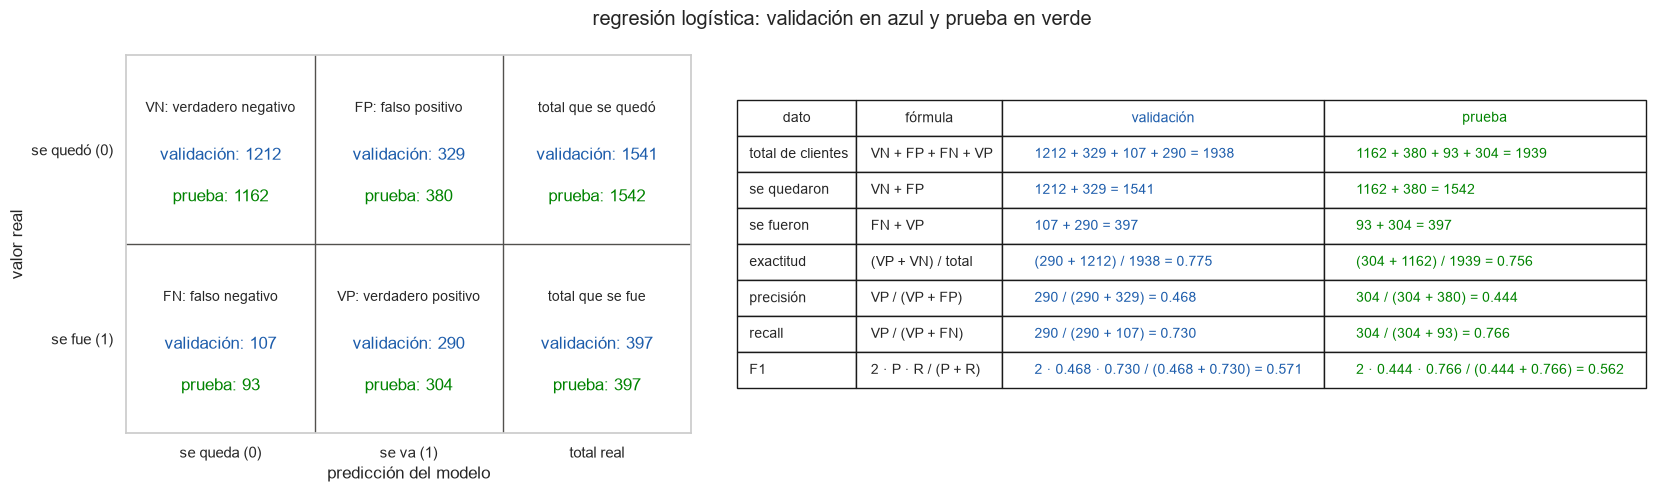

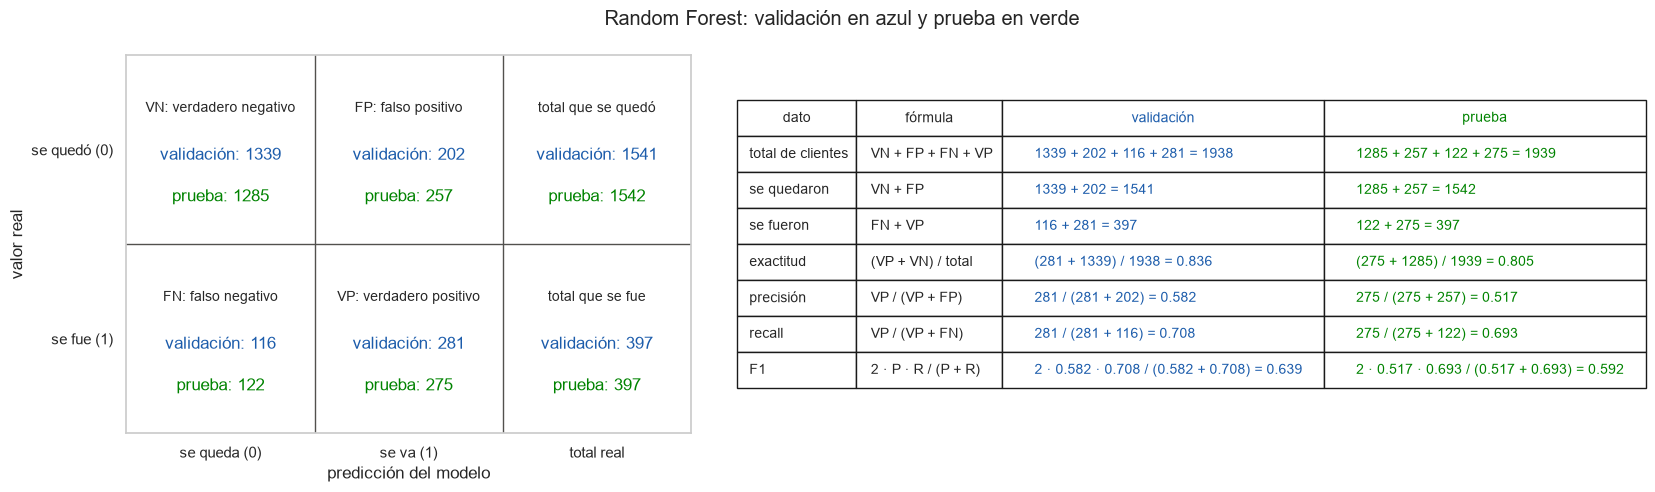

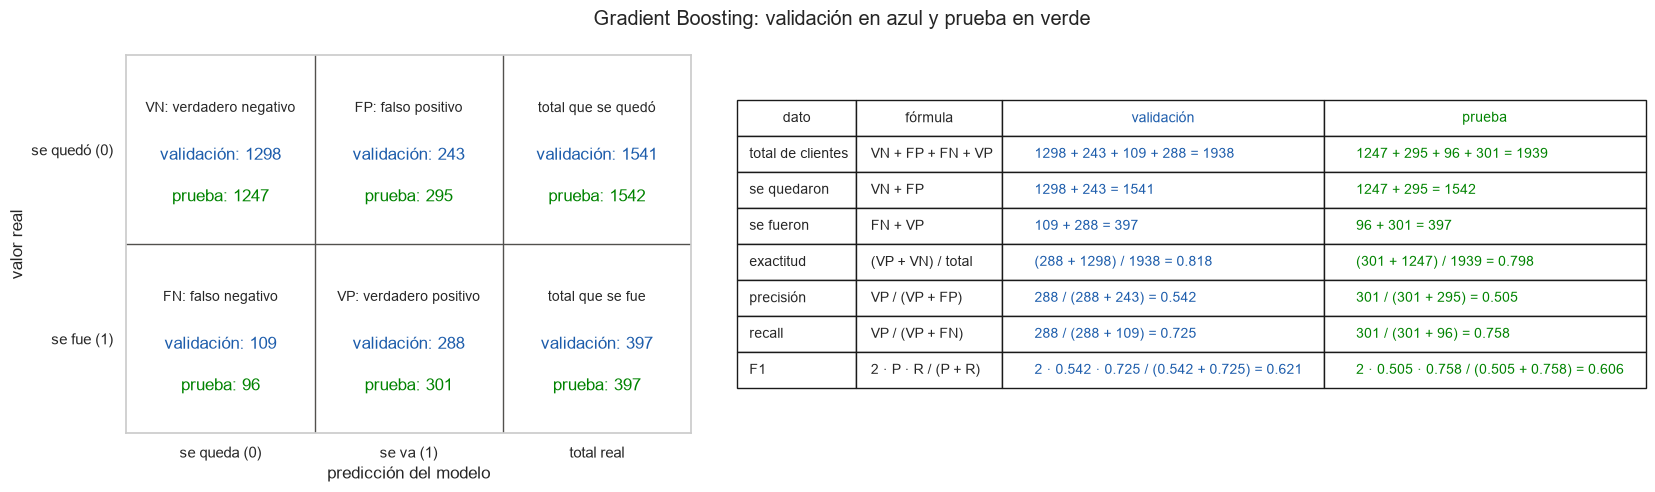

In [32]:
AZUL_VALIDACION, VERDE_PRUEBA = "#1c5cab", "#008300"
NOMBRES_CUADRANTES = [["VN: verdadero negativo", "FP: falso positivo", "total que se quedó"],
                      ["FN: falso negativo", "VP: verdadero positivo", "total que se fue"]]
DATOS_TABLA = [("total de clientes", "VN + FP + FN + VP"), ("se quedaron", "VN + FP"), ("se fueron", "FN + VP"),
               ("exactitud", "(VP + VN) / total"), ("precisión", "VP / (VP + FP)"), ("recall", "VP / (VP + FN)"),
               ("F1", "2 · P · R / (P + R)")]


def calcular_cuentas(matriz):
    """Totales y métricas de una matriz de confusión, escritos como 'cálculo = valor'."""
    (vn, fp), (fn, vp) = matriz
    total = vn + fp + fn + vp
    precision, recall = vp / (vp + fp), vp / (vp + fn)
    return [
        f"{vn} + {fp} + {fn} + {vp} = {total}",
        f"{vn} + {fp} = {vn + fp}",
        f"{fn} + {vp} = {fn + vp}",
        f"({vp} + {vn}) / {total} = {(vp + vn) / total:.3f}",
        f"{vp} / ({vp} + {fp}) = {precision:.3f}",
        f"{vp} / ({vp} + {fn}) = {recall:.3f}",
        f"2 · {precision:.3f} · {recall:.3f} / ({precision:.3f} + {recall:.3f}) = {2 * precision * recall / (precision + recall):.3f}",
    ]


def escribir_cuadrante(eje, columna, fila, nombre, dato_validacion, dato_prueba):
    """Nombre del cuadrante y, debajo, el dato de validación (azul) y el de prueba (verde)."""
    eje.text(columna, fila - 0.22, nombre, ha="center", va="center", fontsize=10)
    eje.text(columna, fila + 0.03, f"validación: {dato_validacion}", ha="center", va="center",
             color=AZUL_VALIDACION, fontsize=12)
    eje.text(columna, fila + 0.25, f"prueba: {dato_prueba}", ha="center", va="center",
             color=VERDE_PRUEBA, fontsize=12)


def graficar_validacion_y_prueba(modelo, titulo):
    """Matriz de confusión con los datos de validación y de prueba en cada cuadrante, y sus métricas al lado."""
    validacion = confusion_matrix(y_validacion, modelo.predict(X_validacion))
    prueba_final = confusion_matrix(y_prueba, modelo.predict(X_prueba))

    fig, (eje_matriz, eje_tabla) = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.3]})
    for fila in range(2):
        for columna in range(2):
            escribir_cuadrante(eje_matriz, columna, fila, NOMBRES_CUADRANTES[fila][columna],
                               validacion[fila, columna], prueba_final[fila, columna])
        escribir_cuadrante(eje_matriz, 2, fila, NOMBRES_CUADRANTES[fila][2],
                           validacion[fila].sum(), prueba_final[fila].sum())
    eje_matriz.set_xlim(-0.5, 2.5)
    eje_matriz.set_ylim(1.5, -0.5)
    eje_matriz.axhline(0.5, color=GRIS, linewidth=1)
    eje_matriz.axvline(0.5, color=GRIS, linewidth=1)
    eje_matriz.axvline(1.5, color=GRIS, linewidth=1)
    eje_matriz.set_xticks([0, 1, 2], ["se queda (0)", "se va (1)", "total real"])
    eje_matriz.set_yticks([0, 1], ["se quedó (0)", "se fue (1)"])
    eje_matriz.set_xlabel("predicción del modelo")
    eje_matriz.set_ylabel("valor real")
    eje_matriz.grid(False)

    filas = [[dato, formula, cuenta_validacion, cuenta_prueba]
             for (dato, formula), cuenta_validacion, cuenta_prueba
             in zip(DATOS_TABLA, calcular_cuentas(validacion), calcular_cuentas(prueba_final))]
    eje_tabla.axis("off")
    tabla = eje_tabla.table(cellText=filas, colLabels=["dato", "fórmula", "validación", "prueba"],
                            loc="center", cellLoc="left")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10)
    tabla.auto_set_column_width(range(4))
    tabla.scale(1.05, 2.2)
    for fila in range(len(filas) + 1):
        tabla[fila, 2].get_text().set_color(AZUL_VALIDACION)
        tabla[fila, 3].get_text().set_color(VERDE_PRUEBA)
    fig.suptitle(f"{titulo}: validación en azul y prueba en verde")
    plt.tight_layout()
    plt.show()


for nombre, modelo in MODELOS.items():
    graficar_validacion_y_prueba(modelo, nombre)

### 3.4 Límites de costo con validación y prueba

Las fórmulas del precio máximo por cliente contactado y del costo de empate entre dos modelos se plantearon en la sección 2.7; aquí no se repiten y solo se aplican a los datos nuevos. Para tener un precio más acertado, además de validación y prueba se usa el promedio de los dos: se promedian los VP y los contactados (VP + FP) de cada modelo, lo que equivale a juntar los 3.877 clientes de ambos conjuntos.

In [33]:
CONJUNTOS = {"validación": (X_validacion, y_validacion), "prueba": (X_prueba, y_prueba)}


def contar_en_cada_conjunto(modelo):
    """VP y contactados (VP + FP) del modelo en validación, en prueba y el promedio de los dos."""
    conteos = {}
    for conjunto, (X, y) in CONJUNTOS.items():
        vn, fp, fn, vp = confusion_matrix(y, modelo.predict(X)).ravel()
        conteos[conjunto] = (vp, vp + fp)
    conteos["promedio"] = ((conteos["validación"][0] + conteos["prueba"][0]) / 2,
                           (conteos["validación"][1] + conteos["prueba"][1]) / 2)
    return conteos


CONTEOS = {nombre: contar_en_cada_conjunto(modelo) for nombre, modelo in MODELOS.items()}
print("VP de los contactados y proporción de contactados que sí se iban:")
pd.DataFrame({nombre: {conjunto: f"{vp:g} de {contactados:g} ({vp / contactados:.1%})"
                       for conjunto, (vp, contactados) in conteos.items()}
              for nombre, conteos in CONTEOS.items()}).T

VP de los contactados y proporción de contactados que sí se iban:


,validación,prueba,promedio
regresión logística,290 de 619 (46.8%),304 de 684 (44.4%),297 de 651.5 (45.6%)
Random Forest,281 de 483 (58.2%),275 de 532 (51.7%),278 de 507.5 (54.8%)
Gradient Boosting,288 de 531 (54.2%),301 de 596 (50.5%),294.5 de 563.5 (52.3%)


In [34]:
def calcular_limites_de_costo(ingreso):
    """Precio máximo de cada modelo y costo de empate entre Gradient Boosting y Random Forest, por conjunto."""
    tabla = {}
    for conjunto in ["validación", "prueba", "promedio"]:
        columna = {}
        for nombre, conteos in CONTEOS.items():
            vp, contactados = conteos[conjunto]
            columna[f"precio máximo {nombre}"] = TASA_DE_EXITO * ingreso * vp / contactados
        vp_gb, contactados_gb = CONTEOS["Gradient Boosting"][conjunto]
        vp_rf, contactados_rf = CONTEOS["Random Forest"][conjunto]
        columna["empate Gradient Boosting vs Random Forest"] = (TASA_DE_EXITO * ingreso * (vp_gb - vp_rf)
                                                                / (contactados_gb - contactados_rf))
        tabla[conjunto] = columna
    return pd.DataFrame(tabla).round()


for ingreso in INGRESOS_ANUALES:
    print(f"Ingreso anual por cliente: {ingreso:,} COP".replace(",", "."))
    display(calcular_limites_de_costo(ingreso))

Ingreso anual por cliente: 500.000 COP


,validación,prueba,promedio
precio máximo regresión logística,70275.0,66667.0,68381.0
precio máximo Random Forest,87267.0,77538.0,82167.0
precio máximo Gradient Boosting,81356.0,75755.0,78394.0
empate Gradient Boosting vs Random Forest,21875.0,60938.0,44196.0


Ingreso anual por cliente: 900.000 COP


,validación,prueba,promedio
precio máximo regresión logística,126494.0,120000.0,123085.0
precio máximo Random Forest,157081.0,139568.0,147901.0
precio máximo Gradient Boosting,146441.0,136359.0,141109.0
empate Gradient Boosting vs Random Forest,39375.0,109688.0,79554.0


**Límites de costo entre Random Forest y Gradient Boosting con el promedio de validación y prueba**

Con un ingreso anual de 500.000 COP por cliente:

| Costo por cliente contactado (COP) | Random Forest | Gradient Boosting | Conviene |
|---|---|---|---|
| menos de 44.196 | gana | **gana más** | Gradient Boosting |
| de 44.196 a 78.394 | **gana más** | gana | Random Forest |
| de 78.394 a 82.167 | **gana** | pierde | Random Forest |
| más de 82.167 | pierde | pierde | ninguno |

Con un ingreso anual de 900.000 COP por cliente:

| Costo por cliente contactado (COP) | Random Forest | Gradient Boosting | Conviene |
|---|---|---|---|
| menos de 79.554 | gana | **gana más** | Gradient Boosting |
| de 79.554 a 141.109 | **gana más** | gana | Random Forest |
| de 141.109 a 147.901 | **gana** | pierde | Random Forest |
| más de 147.901 | pierde | pierde | ninguno |

## 4. Análisis cualitativo del modelo

Las métricas dicen qué tan bien predice el Random Forest; aquí se busca entender cómo decide. Primero el comportamiento global (qué variables pesan más y en qué dirección) y luego una muestra de predicciones individuales. Se usan los clientes del conjunto de prueba, que el modelo no vio al entrenar.

### 4.1 Comportamiento global

**SHAP** explica la probabilidad de irse de cada cliente como una suma. Parte de una probabilidad base, que es el promedio del modelo: 0,50, porque con `class_weight="balanced"` las dos clases pesan lo mismo al entrenar. Cada variable suma o resta a esa base, y el resultado es la probabilidad que da el modelo:

**probabilidad = base + aporte de age + aporte de balance + ... + aporte de active_member**

In [35]:
import shap


def explicar_con_shap(modelo, X):
    """Aportes SHAP a la probabilidad de irse, con los nombres y los valores originales de las variables."""
    explicacion = shap.TreeExplainer(modelo[-1])(modelo[:-1].transform(X))[:, :, 1]
    explicacion.feature_names = [nombre.split("__")[1] for nombre in modelo[:-1].get_feature_names_out()]
    explicacion.data[:, :len(NUMERICAS_MODELO)] = X[NUMERICAS_MODELO].to_numpy()  # edad, saldo y puntaje sin escalar
    return explicacion


def mostrar_suma_shap(explicacion, posicion):
    """Valor y aporte de cada variable para un cliente, y la suma que da su probabilidad."""
    base = explicacion.base_values[posicion]
    aportes = explicacion.values[posicion]
    print(f"base {base:.3f} + suma de aportes {aportes.sum():.3f} = probabilidad {base + aportes.sum():.3f}")
    return pd.DataFrame({"valor": explicacion.data[posicion], "aporte": aportes.round(3)},
                        index=explicacion.feature_names)


explicacion_prueba = explicar_con_shap(random_forest, X_prueba)
print("Probabilidad del modelo para el primer cliente de prueba:",
      random_forest.predict_proba(X_prueba.iloc[[0]])[0, 1].round(3))
mostrar_suma_shap(explicacion_prueba, 0)

Probabilidad del modelo para el primer cliente de prueba: 0.03
base 0.500 + suma de aportes -0.470 = probabilidad 0.030


,valor,aporte
age,25.0,-0.174
balance,0.0,-0.071
credit_score,743.0,-0.010
country_Germany,0.0,-0.015
country_Spain,1.0,0.011
gender_Male,1.0,-0.042
products_number_2,1.0,-0.188
products_number_3,0.0,-0.016
products_number_4,0.0,-0.002
active_member,0.0,0.038


**Importancia y dirección de cada variable.** El primer gráfico promedia el tamaño de los aportes (sin importar el signo) sobre los 1.939 clientes de prueba: es la importancia global. En el segundo, cada punto es un cliente: a la derecha del 0 la variable sube su probabilidad de irse y a la izquierda la baja. El color indica si el valor de la variable es alto (rojo) o bajo (azul).

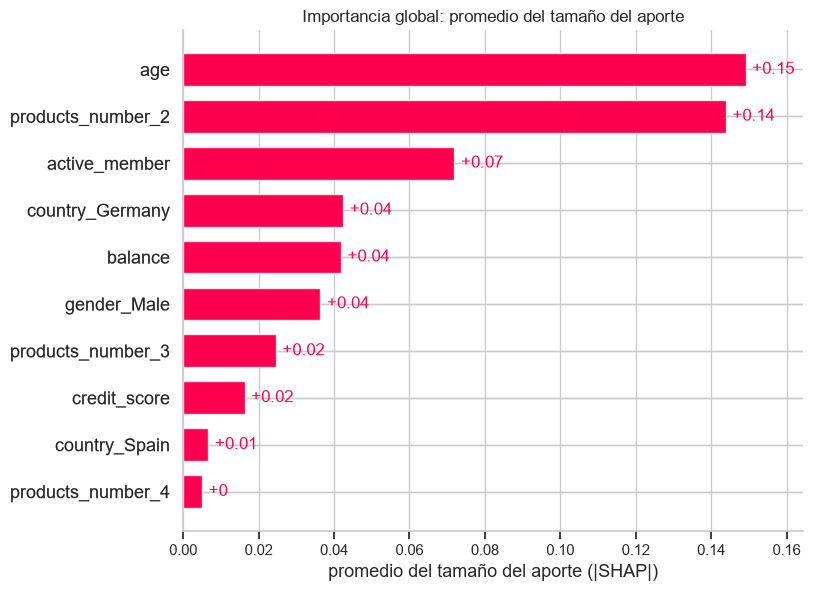

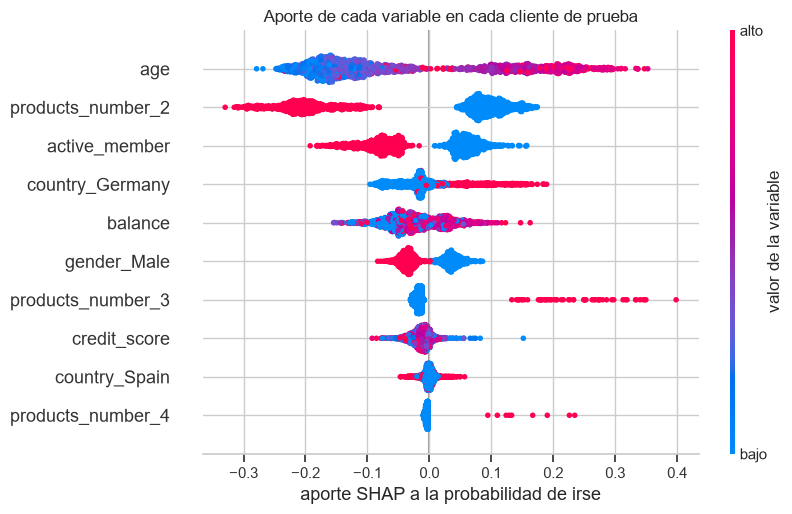

In [36]:
shap.plots.bar(explicacion_prueba, show=False)
plt.title("Importancia global: promedio del tamaño del aporte")
plt.xlabel("promedio del tamaño del aporte (|SHAP|)")
plt.show()

shap.plots.beeswarm(explicacion_prueba, show=False)
plt.title("Aporte de cada variable en cada cliente de prueba")
plt.xlabel("aporte SHAP a la probabilidad de irse")
barra_de_color = plt.gcf().axes[-1]
barra_de_color.set_ylabel("valor de la variable")
barra_de_color.set_yticklabels(["bajo", "alto"])
plt.show()

**ICE (expectativa condicional individual)** toma un cliente, cambia solo una variable y deja todo lo demás igual, para ver cómo cambia su probabilidad de irse. Por ejemplo, con el mismo primer cliente de prueba y variando solo su edad:

In [37]:
def probar_edades(modelo, cliente, edades):
    """Probabilidad de irse de un mismo cliente si solo cambiara su edad."""
    copias = pd.concat([cliente] * len(edades))
    copias["age"] = edades
    return pd.DataFrame({"edad": edades, "probabilidad de irse": modelo.predict_proba(copias)[:, 1].round(3)})


probar_edades(random_forest, X_prueba.iloc[[0]], [25, 35, 45, 55, 65, 75])

,edad,probabilidad de irse
0,25,0.030
1,35,0.030
2,45,0.240
3,55,0.683
4,65,0.647
5,75,0.437


El gráfico repite ese ejercicio con 300 clientes de prueba: cada línea gris es un cliente y la línea naranja es el promedio de todos (dependencia parcial). Se hace con la edad y con el saldo.

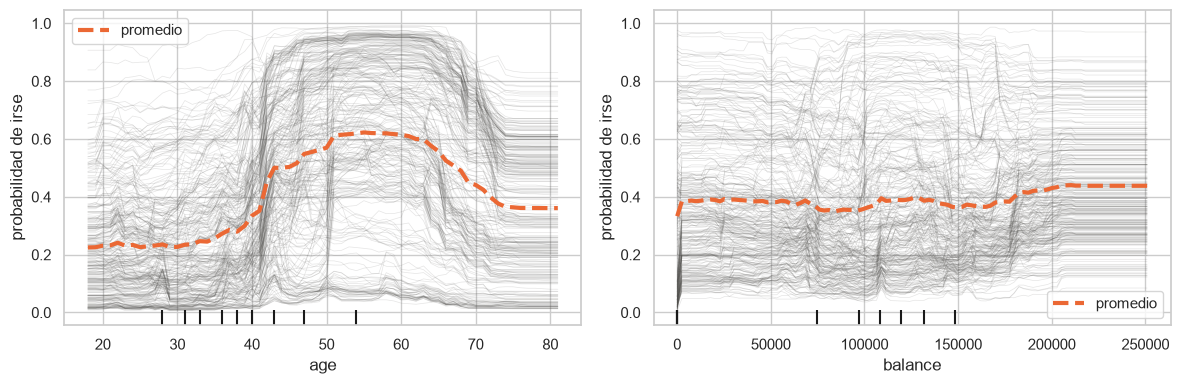

In [38]:
from sklearn.inspection import PartialDependenceDisplay

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(random_forest, X_prueba, ["age", "balance"], kind="both",
                                        subsample=300, random_state=42, percentiles=(0, 1), ax=ejes,
                                        ice_lines_kw={"color": GRIS, "alpha": 0.15},
                                        pd_line_kw={"color": NARANJA, "linewidth": 3, "label": "promedio"})
for eje in fig.axes:
    eje.set_ylabel("probabilidad de irse")
plt.tight_layout()
plt.show()

### 4.2 Predicciones individuales

Se toma un cliente de prueba de cada cuadrante de la matriz de confusión del Random Forest, el caso más marcado de cada uno:

- **VP** (se fue y el modelo lo marcó) y **VN** (se quedó y el modelo acertó): el cliente con el que el modelo estuvo más seguro.
- **FP** (se quedó, pero el modelo lo marcó) y **FN** (se fue y el modelo no lo vio): el cliente con el que el modelo más se equivocó.

In [39]:
def elegir_cliente_por_cuadrante(modelo, X, y):
    """El cliente más marcado de cada cuadrante: mayor riesgo en VP y FP, menor riesgo en FN y VN."""
    riesgo = pd.Series(modelo.predict_proba(X)[:, 1], index=X.index)
    prediccion = modelo.predict(X)
    return {
        "VP: se fue y el modelo lo marcó": riesgo[(y == 1) & (prediccion == 1)].idxmax(),
        "FP: se quedó, pero el modelo lo marcó": riesgo[(y == 0) & (prediccion == 1)].idxmax(),
        "FN: se fue y el modelo no lo vio": riesgo[(y == 1) & (prediccion == 0)].idxmin(),
        "VN: se quedó y el modelo acertó": riesgo[(y == 0) & (prediccion == 0)].idxmin(),
    }


CLIENTES_ELEGIDOS = elegir_cliente_por_cuadrante(random_forest, X_prueba, y_prueba)
clientes = X_prueba.loc[list(CLIENTES_ELEGIDOS.values())].copy()
clientes["se fue"] = y_prueba.loc[clientes.index]
clientes["riesgo del modelo"] = random_forest.predict_proba(clientes[VARIABLES_MODELO])[:, 1].round(3)
clientes.index = list(CLIENTES_ELEGIDOS)
clientes

,age,balance,credit_score,country,gender,products_number,active_member,se fue,riesgo del modelo
VP: se fue y el modelo lo marcó,56.0,111920.13,466.0,Germany,Female,3,0,1,0.992
"FP: se quedó, pero el modelo lo marcó",48.0,111962.99,850.0,Germany,Female,1,0,0,0.969
FN: se fue y el modelo no lo vio,71.0,0.00,779.0,France,Male,2,1,1,0.020
VN: se quedó y el modelo acertó,30.0,0.00,575.0,Spain,Male,2,1,0,0.006


La receta de cada cliente arranca abajo, en el punto de partida del modelo (`E[f(X)]` = 0,50), y cada barra suma (rojo) o resta (azul) hasta llegar arriba a su riesgo final (`f(x)`). Junto a cada variable aparece el valor que tiene ese cliente.

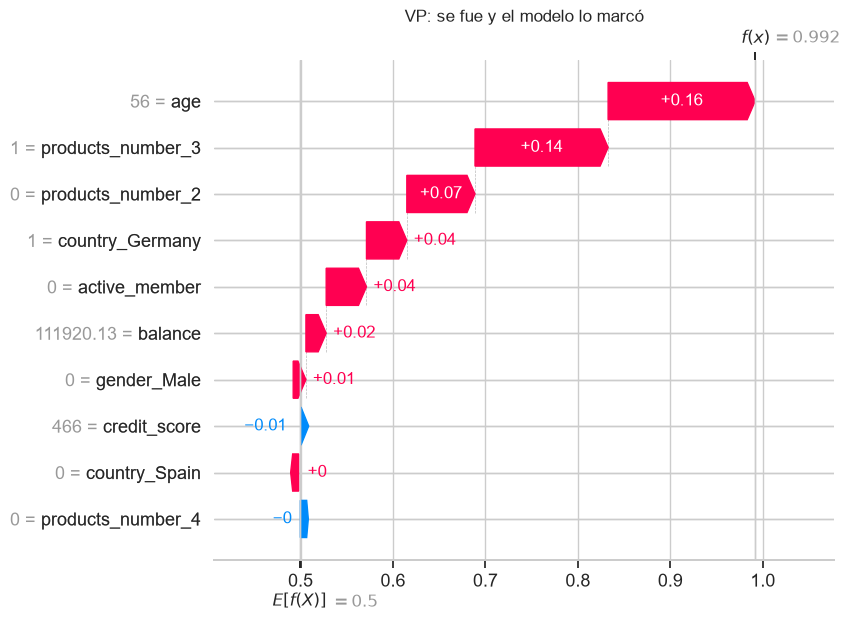

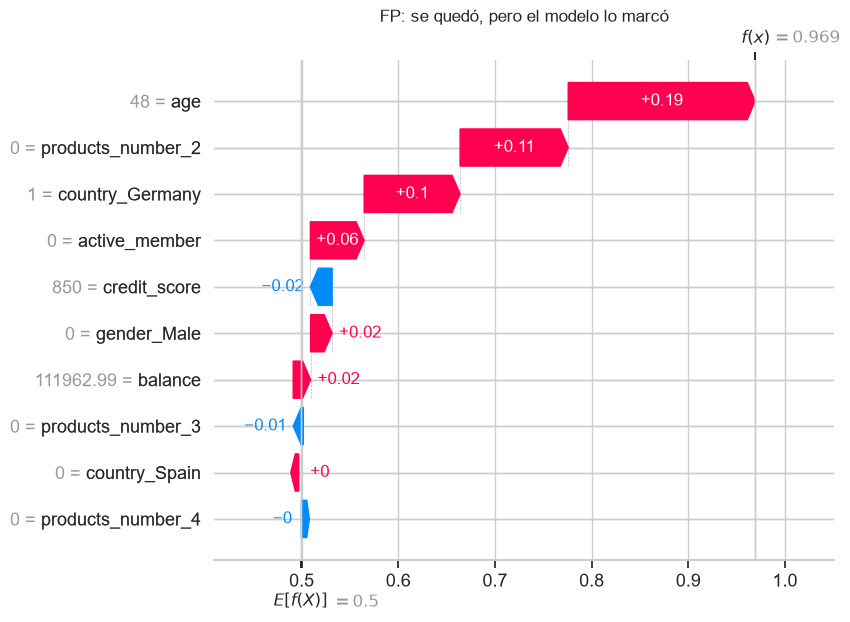

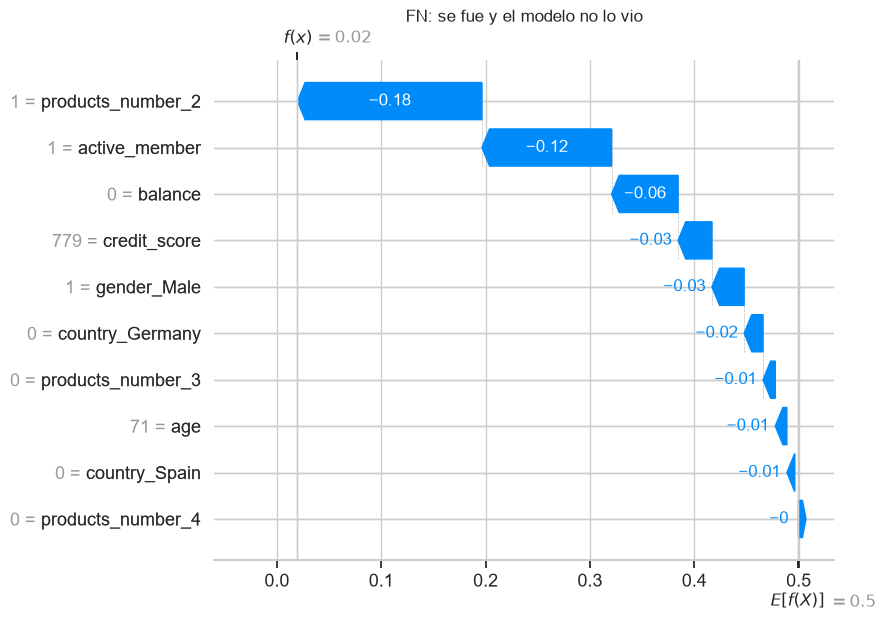

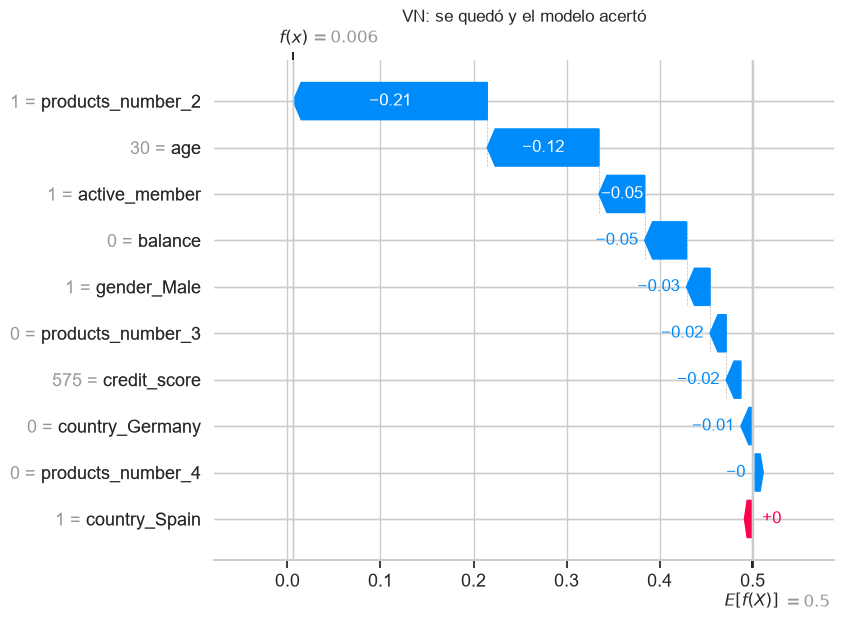

In [40]:
for cuadrante, indice in CLIENTES_ELEGIDOS.items():
    shap.plots.waterfall(explicacion_prueba[X_prueba.index.get_loc(indice)], show=False)
    plt.title(cuadrante)
    plt.show()

### 4.3 Interpretación: cómo funciona el modelo

- El modelo se basa en gran medida en la **edad** y en el **número de productos**: son las dos variables que más mueven el riesgo (0,15 y 0,14 en promedio), seguidas de ser miembro activo (0,07).
- En los casos en que se equivocó, los clientes no se comportaron como los patrones que vimos en la exploración inicial:
  - La clienta que **se quedó, pero el modelo marcó como que se iba** (FP) era una persona de riesgo por la cantidad de productos y la edad: tenía un solo producto (+0,11) y 48 años (+0,19). Además vivía en Alemania (+0,10) y era inactiva (+0,06). Con esos datos, lo esperable según la exploración era que se fuera.
  - El cliente que **se fue y el modelo no lo vio** (FN) no tenía ninguna variable que lo pusiera en un grupo de riesgo: todas le restaron riesgo, sobre todo tener 2 productos (−0,18), ser activo (−0,12) y tener saldo 0 (−0,06). Sus 71 años casi no pesan (−0,01), porque después de los 70 años el abandono baja.
- Por esto podemos decir que el modelo funciona correctamente: su comportamiento es coherente con lo que mostró la exploración, y sus errores vienen de clientes que actuaron distinto a lo que indican sus datos, no de una lógica equivocada del modelo.

## 5. Generación de valor

¿Cuánto cuesta usar el Random Forest en un banco de 20.000 clientes y en cuánto tiempo se recupera la inversión? Cada cliente marcado recibe una llamada y una oferta de tres meses sin cuota de manejo, y cada cliente le deja al banco 900.000 COP al año.

### 5.1 Supuestos y fuentes

| Supuesto | Valor | Fuente | Fecha |
|---|---|---|---|
| Clientes del banco, abandono anual, éxito de la oferta e ingreso anual por cliente | 20.000, 15 %, 30 % y 900.000 COP | Enunciado del taller | — |
| Salario mínimo y auxilio de transporte 2026 | 1.750.905 y 249.095 COP | [Colombia Move](https://colombiamove.com/blog/salario-minimo-colombia-2026-guia/) | jun 2026 |
| Costo total del empleador sobre el salario | 1,52 | [Aleluya](https://aleluya.com/blog/nomina/costo-de-un-empleado-en-colombia-2026/) | 2026 |
| Jornada laboral | 42 horas a la semana | [Bloomberg Línea](https://www.bloomberglinea.com/latinoamerica/colombia/a-quienes-si-y-a-quienes-no-les-aplica-la-reduccion-de-la-jornada-laboral-desde-hoy-en-colombia/) | 15 jul 2026 |
| Llamadas por hora de un agente | 30 | [Outsource Accelerator](https://www.outsourceaccelerator.com/glossary/calls-per-agent-per-hour/) | nov 2026 |
| Llamadas que contesta una persona | 20 % (rango de 10 % a 30 %) | [Sobot](https://www.sobot.io/article/ultimate-glossary-outbound-call-center-metrics/) | nov 2025 |
| Costos de operación del call center | 30 % sobre la hora del agente | **Supuesto propio** | — |
| Oferta: tres meses sin la cuota de manejo más alta | 3 × 44.030 = 132.090 COP | [La República](https://www.larepublica.co/finanzas/cuotas-de-manejo-en-cuentas-de-ahorro-4445937), con datos de la Superfinanciera | 29 jul 2026 |
| Salario del científico/ingeniero de datos (Data Scientist, 3 a 5 años) | 11.000.000 COP al mes | [Michael Page, Guía Salarial Tecnología Colombia 2025](https://image.email.page.com/lib/fe3711717564047b761d70/m/1/3b1b65df-f6f3-4ed3-8d44-fc82a34446d1.pdf), p. 13 | 2025 |
| Salario del líder de negocio (Product, 3 a 5 años) | 13.000.000 COP al mes, con 50 % de dedicación | Michael Page, misma guía, p. 13 | 2025 |
| Nube, capacitación y contingencia | 5.356.050 COP al mes, 10.712.100 COP y 10 % | [Práctica 4 del curso](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/), pasada a pesos con la tasa del 3 nov 2026 ([Portafolio](https://www.portafolio.co/economia/finanzas/el-euro-inicia-a-la-baja-mientras-el-dolar-sube-asi-cotiza-la-moneda-europea-este-martes-3-de-noviembre-505610)) | — |
| Costo de operación | 20 % de la nube y 10 % del científico/ingeniero, cada mes | **Supuesto propio** | — |

Fuentes consultadas el 9 de noviembre de 2026.

### 5.2 Costos

In [41]:
CLIENTES_BANCO, TASA_DE_ABANDONO, INGRESO_ANUAL = 20_000, 0.15, 900_000
SALARIO_MINIMO, AUXILIO_DE_TRANSPORTE, FACTOR_PRESTACIONAL = 1_750_905, 249_095, 1.52
HORAS_AL_MES = 42 * 52 / 12                                        # 42 horas a la semana
LLAMADAS_POR_HORA, TASA_DE_CONTESTA, COSTOS_CALL_CENTER = 30, 0.20, 0.30
CUOTA_DE_MANEJO, MESES_SIN_CUOTA = 44_030, 3
EQUIPO = {"científico/ingeniero de datos": (11_000_000, 1.0, 3),    # salario mensual, dedicación y meses
          "líder de negocio": (13_000_000, 0.5, 3)}
NUBE_AL_MES, CAPACITACION, CONTINGENCIA = 5_356_050, 10_712_100, 0.10   # pesos, pesos y proporción


def pesos(valor, decimales=0):
    """Número con punto de miles y coma decimal, como se escribe en Colombia."""
    return f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def calcular_tasas_de_marcado(modelo):
    """Recall y tasa de falsas alarmas del modelo con validación y prueba juntas, como en la sección 3.4."""
    vn, fp, fn, vp = sum(confusion_matrix(y, modelo.predict(X)) for X, y in CONJUNTOS.values()).ravel()
    return vp / (vp + fn), fp / (fp + vn)


def mostrar_tabla(filas):
    """Tabla de concepto, cálculo y valor, con la última fila en negrita."""
    tabla = pd.DataFrame(filas, columns=["concepto", "cálculo", "valor"])
    return (tabla.style.hide(axis="index")
            .set_properties(**{"text-align": "left"})
            .set_properties(subset=["valor"], **{"text-align": "right"})
            .set_properties(subset=pd.IndexSlice[tabla.index[-1], :], **{"font-weight": "bold"}))


# Clientes del banco que marca el Random Forest
se_van = CLIENTES_BANCO * TASA_DE_ABANDONO
se_quedan = CLIENTES_BANCO - se_van
recall, tasa_falsas_alarmas = calcular_tasas_de_marcado(random_forest)
si_se_iban = round(se_van * recall)
falsas_alarmas = round(se_quedan * tasa_falsas_alarmas)
inscritos = si_se_iban + falsas_alarmas

# Campaña
hora_agente = (SALARIO_MINIMO + AUXILIO_DE_TRANSPORTE) * FACTOR_PRESTACIONAL / HORAS_AL_MES
contactos_por_hora = round(LLAMADAS_POR_HORA * TASA_DE_CONTESTA)
llamada = round(hora_agente / contactos_por_hora * (1 + COSTOS_CALL_CENTER))
oferta = MESES_SIN_CUOTA * CUOTA_DE_MANEJO
costo_unitario = llamada + oferta
costo_campana = inscritos * costo_unitario

# Implementación y operación
implementacion = {nombre: salario * dedicacion * FACTOR_PRESTACIONAL * meses
                  for nombre, (salario, dedicacion, meses) in EQUIPO.items()}
implementacion["nube"] = NUBE_AL_MES * 3
implementacion["capacitación"] = CAPACITACION
implementacion["contingencia"] = CONTINGENCIA * sum(implementacion.values())
costo_implementacion = sum(implementacion.values())
salario_cientifico = EQUIPO["científico/ingeniero de datos"][0]
operacion_al_mes = 0.2 * NUBE_AL_MES + 0.1 * salario_cientifico * FACTOR_PRESTACIONAL
costo_operacion = 12 * operacion_al_mes
costo_total = costo_campana + costo_implementacion + costo_operacion

filas_equipo = [(f"· {nombre}",
                 f"{pesos(salario)} × {pesos(dedicacion * 100)} % × {pesos(FACTOR_PRESTACIONAL, 2)} × {meses} meses",
                 pesos(implementacion[nombre]))
                for nombre, (salario, dedicacion, meses) in EQUIPO.items()]
mostrar_tabla([
    ("Costo unitario de la campaña (por inscrito)", "llamada + oferta", pesos(costo_unitario)),
    ("· llamada", f"hora de agente {pesos(hora_agente)} / {contactos_por_hora} contactos por hora × "
                  f"{pesos(1 + COSTOS_CALL_CENTER, 1)}", pesos(llamada)),
    (f"· oferta: {MESES_SIN_CUOTA} meses sin cuota de manejo", f"{MESES_SIN_CUOTA} × {pesos(CUOTA_DE_MANEJO)}",
     pesos(oferta)),
    ("Cantidad de inscritos (clientes)", f"{pesos(si_se_iban)} + {pesos(falsas_alarmas)}", pesos(inscritos)),
    ("· sí se iban", f"{pesos(se_van)} × {pesos(recall * 100, 1)} %", pesos(si_se_iban)),
    ("· falsas alarmas", f"{pesos(se_quedan)} × {pesos(tasa_falsas_alarmas * 100, 1)} %", pesos(falsas_alarmas)),
    ("Costo total de la campaña con los inscritos", f"{pesos(inscritos)} × {pesos(costo_unitario)}", pesos(costo_campana)),
    ("Costo de implementación del modelo", "suma de los rubros", pesos(costo_implementacion)),
    *filas_equipo,
    ("· nube", f"{pesos(NUBE_AL_MES)} al mes × 3 meses", pesos(implementacion["nube"])),
    ("· capacitación", "pago único", pesos(implementacion["capacitación"])),
    ("· contingencia", f"{pesos(CONTINGENCIA * 100)} % de los rubros anteriores", pesos(implementacion["contingencia"])),
    ("Costo de operación del año", f"{pesos(operacion_al_mes)} al mes × 12", pesos(costo_operacion)),
    ("Costo total del primer año", "campaña + implementación + operación", pesos(costo_total)),
])

concepto,cálculo,valor
Costo unitario de la campaña (por inscrito),llamada + oferta,135.709
· llamada,"hora de agente 16.703 / 6 contactos por hora × 1,3",3.619
· oferta: 3 meses sin cuota de manejo,3 × 44.030,132.090
Cantidad de inscritos (clientes),2.101 + 2.531,4.632
· sí se iban,"3.000 × 70,0 %",2.101
· falsas alarmas,"17.000 × 14,9 %",2.531
Costo total de la campaña con los inscritos,4.632 × 135.709,628.604.088
Costo de implementación del modelo,suma de los rubros,117.238.275
· científico/ingeniero de datos,"11.000.000 × 100 % × 1,52 × 3 meses",50.160.000
· líder de negocio,"13.000.000 × 50 % × 1,52 × 3 meses",29.640.000


### 5.3 Recuperación de la inversión

In [42]:
retenidos = round(TASA_DE_EXITO * si_se_iban)
ganancia_retenidos = retenidos * INGRESO_ANUAL
ganancia_neta_anual = ganancia_retenidos - costo_campana - costo_operacion
ganancia_neta_al_mes = ganancia_neta_anual / 12
ganancia_primer_ano = ganancia_neta_anual - costo_implementacion
if ganancia_neta_al_mes > 0:
    calculo_recuperacion = f"{pesos(costo_implementacion)} / {pesos(ganancia_neta_al_mes)}"
    recuperacion = f"{pesos(costo_implementacion / ganancia_neta_al_mes, 1)} meses"
else:
    calculo_recuperacion = "la ganancia neta al mes es negativa"
    recuperacion = "no se recupera"

mostrar_tabla([
    ("Clientes que sí se iban y se inscriben", "de la tabla de costos", pesos(si_se_iban)),
    ("Cantidad esperada de retención (clientes)", f"{pesos(TASA_DE_EXITO * 100)} % × {pesos(si_se_iban)}",
     pesos(retenidos)),
    ("Ganancia en un año de los retenidos", f"{pesos(retenidos)} × {pesos(INGRESO_ANUAL)}", pesos(ganancia_retenidos)),
    ("Costo total de la campaña", "de la tabla de costos", pesos(-costo_campana)),
    ("Costo de operación del año", "de la tabla de costos", pesos(-costo_operacion)),
    ("Ganancia neta del año, sin contar la inversión", "ganancia − campaña − operación", pesos(ganancia_neta_anual)),
    ("Ganancia neta al mes", f"{pesos(ganancia_neta_anual)} / 12", pesos(ganancia_neta_al_mes)),
    ("Costo de implementación del modelo", "de la tabla de costos", pesos(-costo_implementacion)),
    ("Ganancia neta del primer año, con la inversión", "ganancia neta del año − implementación",
     pesos(ganancia_primer_ano)),
    ("Tiempo de recuperación de la inversión", calculo_recuperacion, recuperacion),
])

concepto,cálculo,valor
Clientes que sí se iban y se inscriben,de la tabla de costos,2.101
Cantidad esperada de retención (clientes),30 % × 2.101,630
Ganancia en un año de los retenidos,630 × 900.000,567.000.000
Costo total de la campaña,de la tabla de costos,-628.604.088
Costo de operación del año,de la tabla de costos,-32.918.520
"Ganancia neta del año, sin contar la inversión",ganancia − campaña − operación,-94.522.608
Ganancia neta al mes,-94.522.608 / 12,-7.876.884
Costo de implementación del modelo,de la tabla de costos,-117.238.275
"Ganancia neta del primer año, con la inversión",ganancia neta del año − implementación,-211.760.883
Tiempo de recuperación de la inversión,la ganancia neta al mes es negativa,no se recupera


### 5.4 Costo máximo de la campaña

Cuánto puede costar la campaña para que el banco no pierda dinero en el primer año, contando la inversión en el modelo.

In [43]:
campana_maxima = ganancia_retenidos - costo_operacion - costo_implementacion

mostrar_tabla([
    ("Ganancia en un año de los retenidos", f"{pesos(retenidos)} × {pesos(INGRESO_ANUAL)}", pesos(ganancia_retenidos)),
    ("Costo de operación del año", "de la tabla de costos", pesos(-costo_operacion)),
    ("Costo de implementación del modelo", "de la tabla de costos", pesos(-costo_implementacion)),
    ("Costo máximo de la campaña en el primer año", "ganancia − operación − implementación",
     pesos(campana_maxima)),
    ("Costo máximo por inscrito", f"{pesos(campana_maxima)} / {pesos(inscritos)}", pesos(campana_maxima / inscritos)),
])

concepto,cálculo,valor
Ganancia en un año de los retenidos,630 × 900.000,567.000.000
Costo de operación del año,de la tabla de costos,-32.918.520
Costo de implementación del modelo,de la tabla de costos,-117.238.275
Costo máximo de la campaña en el primer año,ganancia − operación − implementación,416.843.205
Costo máximo por inscrito,416.843.205 / 4.632,89.992


**En el primer año, el costo total es de 778,8 millones de COP (campaña 628,6 + implementación 117,2 + operación 32,9) y la ganancia de los 630 clientes retenidos es de 567,0 millones: el banco pierde 211,8 millones y la inversión no se recupera. Para no perder en el primer año, la campaña puede costar como máximo 416,8 millones, es decir 89.992 COP por inscrito, frente a los 135.709 que cuesta con tres meses sin cuota de manejo.**